# Customer Support Analysis

**Team:** TwoSeven

**Members:** Lucas Liu, Weijun Fan, Shujun Chen

### Background
Many customers tweet a brand for help when their products go wrong. In late 2017, support teams faced two very different surges: Apple’s iOS 11.1 keyboard bug (released Oct 31, fixed Nov 9) and Amazon’s Black Friday (Nov 24) and Cyber Monday (Nov 27).

### Research Problem
1. Do the posting time and wording affect the response speed?
    - Morning or Night
    - Rude or Polite
2. How do support teams react to a planned peak vs an unplanned emergency?
    - Planned Black Friday vs iOS 11.1 keyboard bug
3. When does similar-case search help?
    - keywords (TF-IDF) or semantic embeddings

### Delivered System
We will deliver a system that accepts a customer's query about the products, and then provide the expected waiting time according to the user's words, posting time and whether it is a peak time, and provide a few related cases for the user to review while they are waiting.

## Data Cleaning

### 1. Read Data

In [1]:
import html
import os
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from langdetect import detect, DetectorFactory # detect language
from tqdm import tqdm # show the data process time

from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

random_seed = 42
brand_colors = {"AmazonHelp": "tab:blue", "AppleSupport": "tab:orange"}

In [2]:
df = pd.read_csv("./data/twcs/twcs.csv")
print("Data Shape: ", df.shape)
df.head()

Data Shape:  (2811774, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0


There are 2,811,774 tweets. Each row is one tweet, with 7 columns:
- `tweet_id`: The unique ID of the tweet.
- `author_id`: The ID or account name of the person or support team that posted the tweet.
- `inbound`: Whether the tweet was sent to a company. `True`: a customer message. `False`: a support message.
- `created_at`: The date and time when the tweet was posted.
- `text`: The text of the tweet.
- `response_tweet_id`: The ID(s) of tweets that replied to this tweet, if any.
- `in_response_to_tweet_id`: The ID of the tweet that this tweet replied to, if any.

### 2. Check Missing and Duplicate Data

In [3]:
# Calculate the missing data count
print("Missing Count:")
print(df.isnull().sum())

both_missing = df[df["response_tweet_id"].isnull() & df["in_response_to_tweet_id"].isnull()]
print("Tweets with both IDs missing:", both_missing.shape[0])

Missing Count:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
Tweets with both IDs missing: 0


- Missing `response_tweet_id`: the tweet is the last one in a conversation.
- Missing `in_response_to_tweet_id`: the tweet starts a conversation.
- No tweet has both IDs missing. So every tweet belongs to a conversation, and every tweet that starts a conversation has at least one reply. The data therefore cannot show how often customers get no reply at all.

Missing IDs do not tell us whether the author is a customer or a support account; the `inbound` column tells us this.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

id_counts = df["tweet_id"].value_counts()
print("Number of repeated tweet IDs:", (id_counts > 1).sum())

Exact duplicate rows: 0
Number of repeated tweet IDs: 0


### 3. Brand Statistics

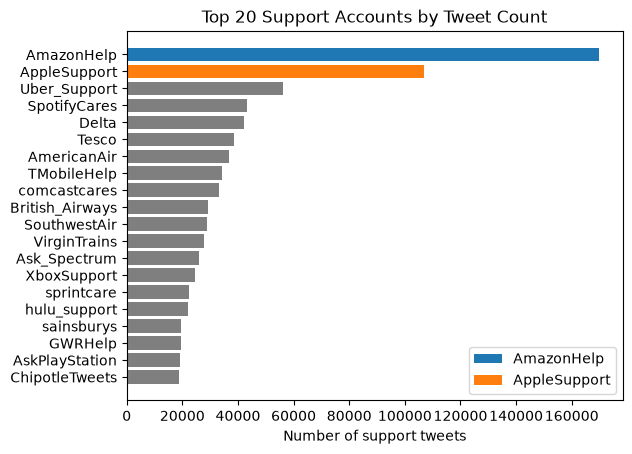

In [5]:
support_tweets = df[df["inbound"] == False]
brand_counts = pd.DataFrame({"Support Tweet Count": support_tweets["author_id"].value_counts()})
top_brands = brand_counts.head(20).sort_values("Support Tweet Count")

# Other accounts in gray, the two brands we study in their own colors
plt.barh(top_brands.index, top_brands["Support Tweet Count"], color="tab:gray")
plt.barh("AmazonHelp", top_brands.loc["AmazonHelp", "Support Tweet Count"], color=brand_colors["AmazonHelp"], label="AmazonHelp")
plt.barh("AppleSupport", top_brands.loc["AppleSupport", "Support Tweet Count"], color=brand_colors["AppleSupport"], label="AppleSupport")
plt.xlabel("Number of support tweets")
plt.title("Top 20 Support Accounts by Tweet Count")
plt.legend()
plt.show()

The chart shows the 20 support accounts with the most tweets. 

AmazonHelp has the most support tweets, followed by AppleSupport. 
For the rest of this project, we will study only Amazon and Apple, including their support tweets and related customer messages.

In all charts of this notebook, AmazonHelp is blue and AppleSupport is orange.

Next, we assign a related brand to each tweet, so that we can safely delete the tweets of other brands.

The algorithm:
- First, label each support tweet with its own account name.
- Then repeat: the tweets labeled in the last round pass their brand to their parent tweets and their replies. Within one round, the brand from the parent tweet is used first.
- Stop when no new tweet gets a brand. Tweets that are not connected to any support tweet stay without a brand.

In [6]:
def find_related_brands(data):
    """Label each tweet with the support account of its conversation.

    Input: a DataFrame of tweets with `tweet_id`, `in_response_to_tweet_id`,
    `author_id` and `inbound`.
    Output: a Series aligned with `data`. It holds the support account name of each
    tweet, or a missing value if the tweet is not connected to any support tweet.
    A tweet keeps the first brand it gets.
    """
    # First label the support tweet.
    messages = data[["tweet_id", "in_response_to_tweet_id"]].copy()
    messages["related_brand"] = data["author_id"].where(data["inbound"] == False)
    # Now, only support tweets have the label.
    # new_labels is the latest updated data every iteration.
    new_labels = messages[messages["related_brand"].notna()]
    # unknown is those who haven't been updated.
    unknown = messages[messages["related_brand"].isna()].copy()

    # Only newly labeled tweets need to pass their brand to unknown tweets.
    while not new_labels.empty and not unknown.empty:
        parent_brand = new_labels.set_index("tweet_id")["related_brand"]
        reply_brand = new_labels.groupby("in_response_to_tweet_id")["related_brand"].first()
        # Within each round, use the parent's brand before a reply's brand.
        unknown["related_brand"] = unknown["in_response_to_tweet_id"].map(parent_brand)
        unknown["related_brand"] = unknown["related_brand"].fillna(unknown["tweet_id"].map(reply_brand))
        new_labels = unknown[unknown["related_brand"].notna()]
        messages.loc[new_labels.index, "related_brand"] = new_labels["related_brand"]
        unknown = unknown[unknown["related_brand"].isna()].copy()

    return messages["related_brand"]

cleaned_df = df.copy()

# Add brand labels, then keep tweets related to Amazon or Apple.
cleaned_df["related_brand"] = find_related_brands(cleaned_df)
print("Tweets before filtering:", cleaned_df.shape[0])
cleaned_df = cleaned_df[cleaned_df["related_brand"].isin(["AmazonHelp", "AppleSupport"])]
print("Tweets after filtering:", cleaned_df.shape[0])
cleaned_df.head()

Tweets before filtering: 2811774
Tweets after filtering: 611145


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand
181,269,AmazonHelp,False,Wed Nov 22 09:23:01 +0000 2017,@115770 こんにちは、アマゾン公式です。Fire TV Stickが見れないというのは...,"270,271",272.0,AmazonHelp
182,270,115770,True,Wed Nov 22 09:24:30 +0000 2017,@AmazonHelp ありがとうございます。\n今、電話で主人が対応していただいてます。,NaN,269.0,AmazonHelp
183,271,115770,True,Wed Nov 22 09:30:36 +0000 2017,@AmazonHelp 電話で対応してもらいましたが改良されませんでした。\n保証期間も過ぎ...,273,269.0,AmazonHelp
184,273,AmazonHelp,False,Wed Nov 22 09:40:27 +0000 2017,@115770 カスタマーサービスにてお問い合わせ済みとのことで、お手数をおかけいたしました...,274,271.0,AmazonHelp
185,274,115770,True,Wed Nov 22 09:44:04 +0000 2017,@AmazonHelp こちらこそありがとうございました。,275,273.0,AmazonHelp


### 4. Check Data Types

In [7]:
print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                     int64
author_id                      str
inbound                       bool
created_at                     str
text                           str
response_tweet_id              str
in_response_to_tweet_id    float64
related_brand                  str
dtype: object


- `tweet_id` is `int64`: it contains integer IDs with no missing values.
- `in_response_to_tweet_id` is `float64`: it contains missing values (`NaN`), which regular `int64` cannot store.
- `response_tweet_id` is `str`: some values contain several reply IDs separated by commas, such as `"5,7"`.
- `created_at` is `str`: it is a timestamp in the string form, which cannot do the subtracting calculation.

So, we turn `tweet_id` and `in_response_to_tweet_id` into `Int64`, turn `response_tweet_id` into a list of `int`, turn `created_at` into `datetime`.

In [8]:
# Convert the str into list
response_ids = []
for response in cleaned_df["response_tweet_id"].fillna(""):
    response_ids.append([int(x) for x in response.split(",") if x != ""])
cleaned_df["response_tweet_id"] = response_ids

# Change type to Int64 (can store NaN)
cleaned_df["tweet_id"] = cleaned_df["tweet_id"].astype("Int64")
cleaned_df["in_response_to_tweet_id"] = cleaned_df["in_response_to_tweet_id"].astype("Int64")

# Change type to datetime
cleaned_df["created_at"] = pd.to_datetime(cleaned_df["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)

print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                                 Int64
author_id                                  str
inbound                                   bool
created_at                 datetime64[us, UTC]
text                                       str
response_tweet_id                       object
in_response_to_tweet_id                  Int64
related_brand                              str
dtype: object


### 5. Check Time Range

Earliest tweet: 2011-10-13 11:57:18+00:00
Latest tweet: 2017-12-03 23:13:02+00:00


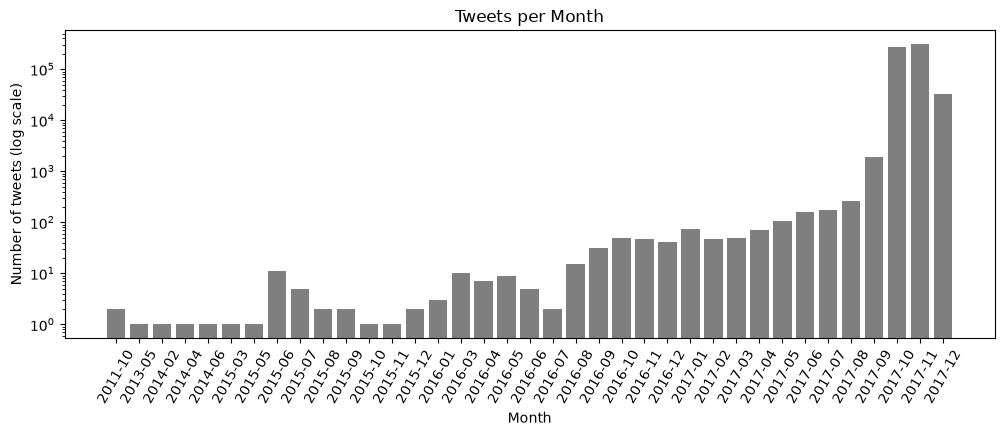

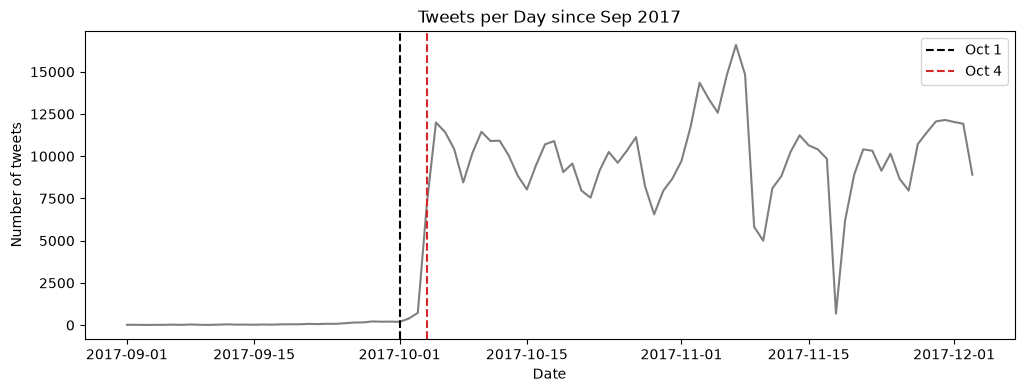

In [9]:
print("Earliest tweet:", cleaned_df["created_at"].min())
print("Latest tweet:", cleaned_df["created_at"].max())

# Count tweets per month (log scale, because early months are very small)
month_counts = pd.DataFrame({"Tweet Count": cleaned_df["created_at"].dt.strftime("%Y-%m").value_counts().sort_index()})

plt.figure(figsize=(12, 4))
plt.bar(month_counts.index, month_counts["Tweet Count"], color="tab:gray")
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Month")
plt.ylabel("Number of tweets (log scale)")
plt.title("Tweets per Month")
plt.show()

# Zoom in: count tweets per day since Sep 2017
recent = cleaned_df[cleaned_df["created_at"] >= "2017-09-01"]
day_counts = recent["created_at"].dt.date.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts.values, color="tab:gray")
plt.axvline(pd.Timestamp("2017-10-01"), color="black", linestyle="--", label="Oct 1")
plt.axvline(pd.Timestamp("2017-10-04"), color="tab:red", linestyle="--", label="Oct 4")
plt.xlabel("Date")
plt.ylabel("Number of tweets")
plt.title("Tweets per Day since Sep 2017")
plt.legend()
plt.show()

Most tweets are from October to early December 2017. Before that, each month has only a few tweets.

- These early tweets are scattered. They were likely pulled in because later conversations replied to them.
- The daily count jumps from a few hundred to over 6,000 on Oct 4, 2017, so continuous data collection starts there.
- We keep tweets from Oct 4, 2017 onward and remove the earlier ones.
- Both events for RQ2 come after this date: the iOS 11.1 keyboard bug (Oct 31 - Nov 9) and Black Friday / Cyber Monday (Nov 24 - Nov 27). RQ2 compares each event with the 14 days just before it, which also come after Oct 4.
- Three days have far fewer tweets than the days around them (the dips in the daily plot): Nov 9 and Nov 10 have about 5,000 - 6,000 tweets, while the weekdays around them have 10,000 or more, and Nov 18 has fewer than 1,000. Both brands drop on the same days (see RQ2, Section 1), so these days probably have missing data, but we cannot confirm this. We keep them but flag them: RQ2 also checks its results without these days.

In [10]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep tweets from Oct 4, 2017
cleaned_df = cleaned_df[cleaned_df["created_at"] >= "2017-10-04"]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Earliest tweet:", cleaned_df["created_at"].min())

Tweets before filtering: 611145
Tweets after filtering: 606758
Earliest tweet: 2017-10-04 00:00:00+00:00


### 6. Detect Language

Some tweets are not in English.
Our text analysis (rude or polite words, TF-IDF, embeddings) only works for English, so we check the language of each tweet.

We use the characters in the text to guess the language:
- Hiragana or Katakana: Japanese (`japan`)
- Hangul: Korean (`korean`)
- Chinese characters: Chinese (`china`)
- Latin letters only: English or other western languages (`latin`)
- None of the above: `other`

Mentions (`@xxx`) and links are removed first, because they are always in Latin letters.

In [11]:
text = cleaned_df["text"].str.replace(r"@\w+|https?://\S+", "", regex=True)

cleaned_df["language"] = np.select(
    [text.str.contains("[\u3040-\u30ff]"),
     text.str.contains("[\uac00-\ud7af]"),
     text.str.contains("[\u4e00-\u9fff]"),
     text.str.contains("[A-Za-z]")],
    ["japan", "korean", "china", "latin"],
    default="other"
)

Tweets with the `latin` tag still include many non-English languages (Spanish, French, ...). So we use the `langdetect` package. It is slow on a large dataset, so we only run it on `latin` tweets.

We only remove non-English **customer** tweets, and keep all support tweets:
- `langdetect` sometimes labels a short English reply as another language, e.g. "Please keep us posted. ^MC".
- If the first support reply is removed, the case is lost, or a later reply is used as the first reply and the waiting time becomes too long.
- Support replies in other languages do no harm: they usually reply to non-English customer tweets, which are removed, so they are never paired into a case.

In [12]:
DetectorFactory.seed = random_seed

latin_text = text[cleaned_df["language"] == "latin"]
short = latin_text.str.split().str.len() <= 4

detected = []
for t in tqdm(latin_text[~short], desc="Detecting language"):
    try:
        detected.append(detect(t))
    except Exception:
        detected.append("unknown")

cleaned_df.loc[latin_text[short].index, "language"] = "en"
cleaned_df.loc[latin_text[~short].index, "language"] = detected

language_counts = pd.DataFrame({"Tweet Count": cleaned_df["language"].value_counts()})
language_counts.head()


Detecting language: 100%|██████████| 554279/554279 [06:08<00:00, 1503.57it/s]


,Tweet Count
language,
en,519059
japan,19982
es,19535
fr,18370
de,10318


In [13]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep English customer tweets and all support tweets
cleaned_df = cleaned_df[(cleaned_df["language"] == "en") | (cleaned_df["inbound"] == False)]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Support tweets kept without the en label:", ((cleaned_df["language"] != "en") & (cleaned_df["inbound"] == False)).sum())

Tweets before filtering: 606758
Tweets after filtering: 555973
Support tweets kept without the en label: 36914


### 7. Fix Broken Reply Links

The filters above delete some tweets in the middle of a conversation. So some tweets still link to tweets that are no longer in `cleaned_df`:
- `in_response_to_tweet_id` may point to a deleted parent tweet.
- `response_tweet_id` may contain deleted reply tweets.

We do not delete these tweets, because many of them are still useful. For example, a customer tweet whose parent was deleted may still have a support reply, which we need for the waiting time.

So we only fix the links:
- If the parent tweet was deleted, set `in_response_to_tweet_id` to missing, and treat the tweet as the start of a conversation.
- Remove the deleted IDs from `response_tweet_id`.

In [14]:
kept_ids = set(cleaned_df["tweet_id"])

broken_parent = cleaned_df["in_response_to_tweet_id"].notna() & ~cleaned_df["in_response_to_tweet_id"].isin(kept_ids)
print("Tweets whose parent was deleted:", broken_parent.sum())
cleaned_df.loc[broken_parent, "in_response_to_tweet_id"] = pd.NA

new_responses = []
broken_replies = 0
for responses in cleaned_df["response_tweet_id"]:
    kept = [x for x in responses if x in kept_ids]
    broken_replies += len(responses) - len(kept)
    new_responses.append(kept)
cleaned_df["response_tweet_id"] = new_responses
print("Reply links pointing to deleted tweets:", broken_replies)

print("Final number of tweets:", cleaned_df.shape[0])

Tweets whose parent was deleted: 45708


Reply links pointing to deleted tweets: 39749
Final number of tweets: 555973


### 8. Save Cleaned DataFrame

In [15]:
cleaned_df.to_pickle("./data/cleaned_df.pkl")
print("Saved", cleaned_df.shape[0], "tweets to ./data/cleaned_df.pkl")

Saved 555973 tweets to ./data/cleaned_df.pkl


Later sections load `cleaned_df.pkl` directly, so the slow language detection (about 6 minutes) does not need to run again.

### 9. Pair Customer Tweets with Replies

All three research questions use **cases**. A case is one customer tweet paired with the first brand reply to it.

- Split the tweets into customer tweets (`inbound == True`) and support tweets (`inbound == False`).
- Match a customer tweet's `tweet_id` to a support tweet's `in_response_to_tweet_id`. Columns from the two sides get the suffixes `_customer` and `_reply`.
- Keep only pairs where the reply author is the case's brand. A few customer tweets mention both brands, and we do not want the other brand's reply.
- If a customer tweet has several replies, keep the earliest one.
- Customer tweets with no reply are left out, since they have no waiting time.
- `is_first_tweet`: `True` if the customer tweet starts a conversation, `False` if it is a follow-up inside a conversation. We keep both kinds.
- `response_minutes`: the waiting time in minutes, from the customer tweet to the first brand reply.

In [16]:
cleaned_df = pd.read_pickle("./data/cleaned_df.pkl")

# Split
customer = cleaned_df[cleaned_df["inbound"] == True]
support = cleaned_df[cleaned_df["inbound"] == False]

# Pair each customer tweet with the support replies to it
cases = customer.merge(support, left_on="tweet_id", right_on="in_response_to_tweet_id", suffixes=("_customer", "_reply"))
print("Customer-reply pairs:", cases.shape[0])

# Keep replies from the right brand, then keep only the earliest reply
cases = cases[cases["author_id_reply"] == cases["related_brand_customer"]]
cases = cases.sort_values("created_at_reply").drop_duplicates("tweet_id_customer")
# A first tweet does not reply to any other tweet
cases["is_first_tweet"] = cases["in_response_to_tweet_id_customer"].isna()
# Waiting time in minutes
cases["response_minutes"] = (cases["created_at_reply"] - cases["created_at_customer"]).dt.total_seconds() / 60
print("Cases after keeping the first brand reply:", cases.shape[0])
cases[["tweet_id_customer", "tweet_id_reply", "created_at_customer", "created_at_reply", "related_brand_customer", "is_first_tweet", "response_minutes"]].head()

Customer-reply pairs: 231529


Cases after keeping the first brand reply: 219324


,tweet_id_customer,tweet_id_reply,created_at_customer,created_at_reply,related_brand_customer,is_first_tweet,response_minutes
102158,1286995,1286994,2017-10-04 00:04:13+00:00,2017-10-04 00:12:31+00:00,AmazonHelp,False,8.300000
102157,1286993,1286992,2017-10-04 00:24:40+00:00,2017-10-04 00:33:30+00:00,AmazonHelp,False,8.833333
17297,243032,243030,2017-10-04 00:07:40+00:00,2017-10-04 00:36:31+00:00,AppleSupport,True,28.850000
32359,387506,387504,2017-10-04 00:15:29+00:00,2017-10-04 00:37:54+00:00,AppleSupport,False,22.416667
17225,242530,242529,2017-10-04 00:32:37+00:00,2017-10-04 00:58:51+00:00,AppleSupport,True,26.233333


### 10. Check Waiting Time

Cases waiting more than 24 hours: 75


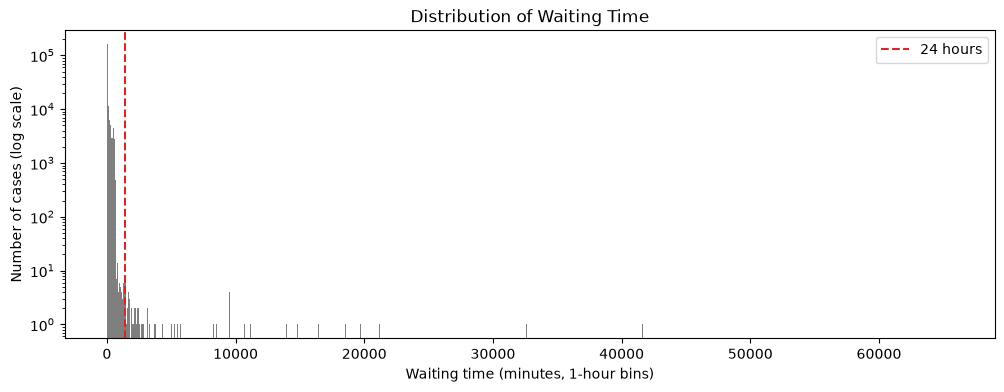

,Waiting Time (min)
count,219324.000000
mean,79.633332
std,258.016401
min,0.766667
25%,9.050000
50%,21.483333
75%,69.150000
max,65653.433333


In [17]:
print("Cases waiting more than 24 hours:", (cases["response_minutes"] > 24 * 60).sum())

# Waiting time histogram with 1-hour bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, cases["response_minutes"].max() + 60, 60), color="tab:gray")
plt.axvline(24 * 60, color="tab:red", linestyle="--", label="24 hours")
plt.yscale("log")
plt.xlabel("Waiting time (minutes, 1-hour bins)")
plt.ylabel("Number of cases (log scale)")
plt.title("Distribution of Waiting Time")
plt.legend()
plt.show()

pd.DataFrame({"Waiting Time (min)": cases["response_minutes"].describe()})

Most cases get a reply within a few hours. Only 75 cases wait more than 24 hours, and they are spread thinly over a long tail up to about 45 days.

- These very late replies are unlikely to be a normal first response to the customer.
- They are only about 0.03% of the cases, but they pull the mean up.
- We remove cases that wait more than 24 hours, then plot the distribution again.
- The data ends on Dec 3, 2017. A customer tweet posted in the last 24 hours before the end had less than 24 hours to get a reply, and a late reply would not be in the data. Only its fast replies are recorded, so the waiting time looks too short. We remove these cases too, so every kept case had a full 24 hours to get a reply.

Cases before removing long waits: 219324
Cases after removing long waits: 219249
Data ends at: 2017-12-03 23:13:02+00:00
Cases after removing the last 24 hours: 215852


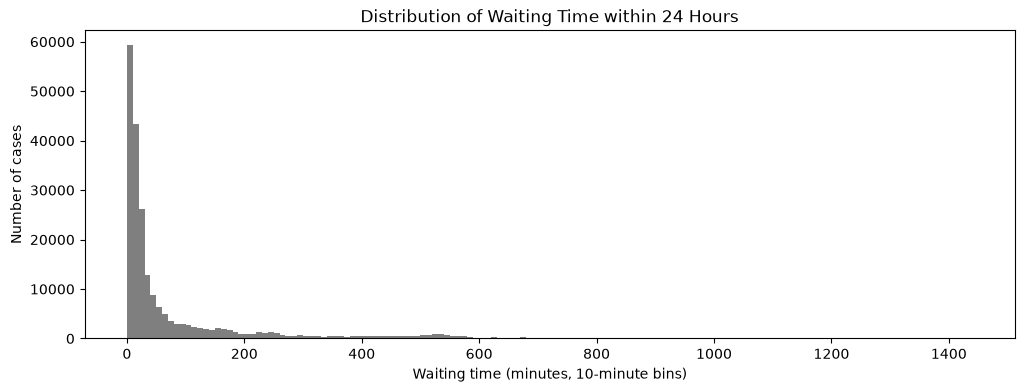

,Waiting Time (min)
count,215852.000000
mean,77.747139
std,131.975013
min,0.766667
25%,9.150000
50%,21.683333
75%,69.900000
max,1435.466667


In [18]:
print("Cases before removing long waits:", cases.shape[0])
# Remove cases that waited more than 24 hours
cases = cases[cases["response_minutes"] <= 24 * 60].copy()
print("Cases after removing long waits:", cases.shape[0])

# Remove cases posted in the last 24 hours before the data ends
data_end = cleaned_df["created_at"].max()
minutes_to_end = (data_end - cases["created_at_customer"]).dt.total_seconds() / 60
cases = cases[minutes_to_end >= 24 * 60].copy()
print("Data ends at:", data_end)
print("Cases after removing the last 24 hours:", cases.shape[0])

# Plot again with 10-minute bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, 24 * 60 + 10, 10), color="tab:gray")
plt.xlabel("Waiting time (minutes, 10-minute bins)")
plt.ylabel("Number of cases")
plt.title("Distribution of Waiting Time within 24 Hours")
plt.show()

pd.DataFrame({"Waiting Time (min)": cases["response_minutes"].describe()})

### 11. Save Cases

We keep the columns needed by the three research questions and give them clear names. Each row of `cases.pkl` is one case.

- `case_id`: the ID of the customer tweet. It is unique for each case.
- `brand`: the support account, `AmazonHelp` or `AppleSupport`.
- `customer_id`: the ID of the customer.
- `customer_text`: the text of the customer tweet.
- `created_at`: the time when the customer tweet was posted (UTC).
- `is_first_tweet`: whether the customer tweet starts a conversation.
- `reply_tweet_id`: the ID of the first brand reply.
- `reply_text`: the text of the first brand reply.
- `reply_at`: the time when the first brand reply was posted (UTC).
- `response_minutes`: the waiting time in minutes, from `created_at` to `reply_at`.

In [19]:
# Old column name -> new column name
new_names = {
    "tweet_id_customer": "case_id",
    "related_brand_customer": "brand",
    "author_id_customer": "customer_id",
    "text_customer": "customer_text",
    "created_at_customer": "created_at",
    "is_first_tweet": "is_first_tweet",
    "tweet_id_reply": "reply_tweet_id",
    "text_reply": "reply_text",
    "created_at_reply": "reply_at",
    "response_minutes": "response_minutes",
}
# Keep only these columns, rename them and sort by time
cases = cases[list(new_names.keys())].rename(columns=new_names)
cases = cases.sort_values("created_at").reset_index(drop=True)

# Save for RQ1, RQ2 and RQ3
cases.to_pickle("./data/cases.pkl")
print("Saved", cases.shape[0], "cases to ./data/cases.pkl")
cases.head()

Saved 215852 cases to ./data/cases.pkl


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,True,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


## Effect of Posting Time and Wording (RQ1)

**RQ1: Do posting time and wording affect how fast support teams respond?**

- **Section 1 - Posting time:** do tweets posted at different hours wait different amounts of time?
- **Section 2 - Wording:** do polite tweets get faster replies than rude ones?

We use the cases built in Data Cleaning (Sections 9 - 11). We compare **medians**, because a few very long waits would pull the mean up, and we analyze the two brands separately.

### 1. Effect of Posting Time

#### Local Time and Peak Events

We load the cases saved in Data Cleaning. `created_at` is stored in UTC, so we convert it to US Eastern Time (we assume most customers are in the US).

Each brand had one peak event in this period. To check that the posting-time results are not driven by these unusual days, we show each of them twice: **all days**, and **without the brand's own peak event**.

- **AppleSupport:** iOS 11.1 keyboard bug, Oct 31 - Nov 9, 2017. This window also includes the iPhone X launch (Nov 3), so it has more than one cause (see RQ2); we still call it the iOS bug period for short.
- **AmazonHelp:** Black Friday to Cyber Monday, Nov 24 - 27, 2017

We also group the 24 hours into four buckets: Morning (6-12), Afternoon (12-18), Evening (18-24) and Night (0-6).

In [20]:
cases = pd.read_pickle("./data/cases.pkl")
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")
cases["hour"] = cases["local_time"].dt.hour

def time_of_day(h):
    """Map an hour to a time-of-day bucket.

    Input: an hour from 0 to 23.
    Output: "Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)" or "Night (0-6)".
    """
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)
time_order = ["Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)", "Night (0-6)"]

# Each brand's own peak event (end date is exclusive)
events = {
    "AppleSupport": ("2017-10-31", "2017-11-10"),   # iOS 11.1 keyboard bug
    "AmazonHelp": ("2017-11-24", "2017-11-28"),     # Black Friday to Cyber Monday
}
cases["in_event"] = False
for brand, (start, end) in events.items():
    mask = (cases["brand"] == brand) & (cases["local_time"] >= start) & (cases["local_time"] < end)
    cases.loc[mask, "in_event"] = True

# The two versions of the data used in this section
versions = {"All days": cases, "Without peak event": cases[~cases["in_event"]]}

pd.DataFrame({
    "Cases in Peak Event": cases.groupby("brand")["in_event"].sum(),
    "Share in Peak Event": cases.groupby("brand")["in_event"].mean().round(3),
})

,Cases in Peak Event,Share in Peak Event
brand,,
AmazonHelp,9008,0.078
AppleSupport,28446,0.285


#### Waiting Time by Hour

The y-axis uses a log scale so both brands fit on one chart.

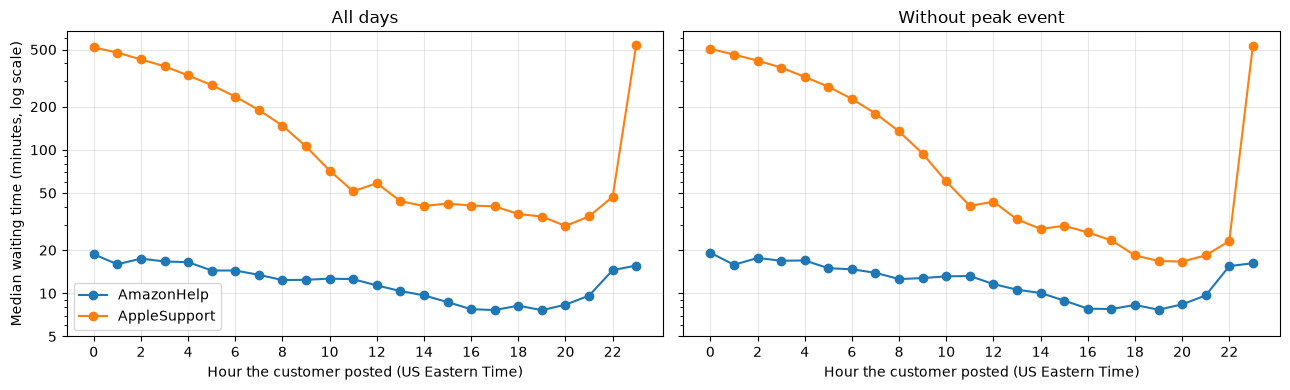

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, data) in zip(axes, versions.items()):
    hourly = data.groupby(["hour", "brand"])["response_minutes"].median().unstack()
    for brand in hourly.columns:
        ax.plot(hourly.index, hourly[brand], marker="o", label=brand, color=brand_colors[brand])
    ax.set_yscale("log")
    ax.set_yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
    ax.set_xticks(range(0, 24, 2))
    ax.set_title(title)
    ax.set_xlabel("Hour the customer posted (US Eastern Time)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Median waiting time (minutes, log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

#### Waiting Time by Time of Day

In [22]:
# Median wait by brand and time of day, for both versions of the data
time_table = pd.DataFrame({
    "Median Wait (min), All Days": versions["All days"].groupby(["brand", "time_of_day"])["response_minutes"].median(),
    "Median Wait (min), Without Peak Event": versions["Without peak event"].groupby(["brand", "time_of_day"])["response_minutes"].median(),
})
time_table.reindex(time_order, level="time_of_day").round(1)

Median Wait (min), All Days  \
brand        time_of_day                                      
AmazonHelp   Morning (6-12)                            13.0   
             Afternoon (12-18)                          9.3   
             Evening (18-24)                           10.0   
             Night (0-6)                               16.4   
AppleSupport Morning (6-12)                           117.6   
             Afternoon (12-18)                         44.5   
             Evening (18-24)                           42.1   
             Night (0-6)                              438.7   

                                Median Wait (min), Without Peak Event  
brand        time_of_day                                               
AmazonHelp   Morning (6-12)                                      13.4  
             Afternoon (12-18)                                    9.5  
             Evening (18-24)                                     10.2  
             Night (0-6)                                         16.7  
AppleSupport Morning (6-12)                                      95.0  
             Afternoon (12-18)                                   31.5  
             Evening (18-24)                                     23.5  
             Night (0-6)                                        417.6

#### Findings: Posting Time

- **AmazonHelp replies fast at every time of day** (median 9-16 min). Night posts (0-6) wait a little longer (16.4 min) than afternoon posts (9.3 min). Removing Black Friday to Cyber Monday changes almost nothing (9.5-16.7 min): Amazon was actually slightly *faster* on those busy days, so the hourly pattern is Amazon's normal behavior.
- **AppleSupport depends strongly on posting time.** Over all days, night posts wait 439 min (over 7 hours) vs 45 min in the afternoon, about **10 times longer**. The curve jumps at **23:00 ET** and falls slowly until about 11:00, which suggests Apple mostly stops replying late at night.
- **The iOS bug period made Apple much slower during the day, but barely changed the night wait.** Without the bug period (28.5% of Apple's cases), afternoon and evening waits drop to 32 and 24 min, while night waits stay at 418 min (439 min over all days). So the night delay is not caused by the bug; without it, night posts wait about 13-18 times longer than afternoon or evening posts.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.

### 2. Effect of Wording

#### Polite and Rude Words

We remove @mentions and links, then flag polite and rude tweets with **regular expressions**. The word lists were built in rounds: we started from common words, then read random unflagged tweets and added the words we had missed.

- `\b` is a word boundary, so `hate` does not match "whatever".
- `\w*` allows extra letters, so `\w*fuck\w*` matches "fucking".
- `thank(?:s|you|u)?` matches "thanks" but not "Thanksgiving".

In [23]:
# Remove @mentions and links so they don't affect word matching
text = (cases["customer_text"]
        .str.replace(r"@\w+", "", regex=True)
        .str.replace(r"http\S+", "", regex=True))

thanks_words = [r"thank(?:s|you|u)?", "thx", "ty"]
other_polite_words = [
    "please", "pls", "plz", r"appreciate\w*", "grateful", "kindly", "sorry", "excuse me",
    "could you", "would you", "regards", "dear", "hi", "hello", r"good (?:morning|afternoon|evening)",
]
rude_words = [
    r"\w*fuck\w*", r"fuk\w*", r"\w*shit\w*", r"damn\w*", r"goddam\w*", "wtf", r"crap\w*", "hell",
    "ass", r"asshole\w*", "pissed", r"screw(?:ed|s)?", "stupid", r"idiot\w*", "dumb", "ridiculous",
    "worst", "terrible", "awful", "horrible", "useless", "pathetic", "rubbish", "garbage", "trash",
    "joke", "hate", r"sucks?", "annoying", "unacceptable", "disgusting", "incompetent", "clueless",
    "lame", r"scam\w*", r"cheat\w*", r"fraud\w*", r"liars?",
]

def flag(words):
    """Flag the tweets that contain any of the words.

    Input: a list of words or regular expressions.
    Output: a boolean Series aligned with `text` (the customer tweets without
    @mentions and links), True if the tweet contains one of the words as a
    whole word, in any case.
    """
    pattern = r"\b(?:" + "|".join(words) + r")\b"
    return text.str.contains(pattern, case=False, regex=True)

cases["has_thanks"] = flag(thanks_words)
cases["is_polite_other"] = flag(other_polite_words)
cases["is_polite"] = cases["has_thanks"] | cases["is_polite_other"]
cases["is_rude"] = flag(rude_words)

print("Share of tweets with polite words:", round(cases["is_polite"].mean(), 3))
print("Share of tweets with rude words:", round(cases["is_rude"].mean(), 3))

Share of tweets with polite words: 0.175
Share of tweets with rude words: 0.146


#### Tone Groups

A tweet can contain both polite and rude words (*"please fix this shit"*), so we put each tweet into exactly one group:

- **Polite:** polite words, no rude words.
- **Neutral:** no polite words and no rude words.
- **Mixed:** both polite and rude words.
- **Rude:** rude words, no polite words.

In [24]:
cases["tone"] = np.select(
    [cases["is_polite"] & cases["is_rude"], cases["is_polite"], cases["is_rude"]],
    ["Mixed", "Polite", "Rude"],
    default="Neutral",
)
tone_order = ["Polite", "Neutral", "Mixed", "Rude"]

pd.DataFrame({"Share of Tweets": cases["tone"].value_counts(normalize=True).reindex(tone_order).round(3)})

,Share of Tweets
tone,
Polite,0.157
Neutral,0.697
Mixed,0.018
Rude,0.128


#### Waiting Time by Tone

In [25]:
tone_table = cases.groupby(["brand", "tone"])["response_minutes"].median().unstack()
print("Median wait (min) by brand and tone:")
tone_table.reindex(columns=tone_order).round(1)

Median wait (min) by brand and tone:


tone,Polite,Neutral,Mixed,Rude
brand,,,,
AmazonHelp,12.5,11.6,13.3,12.8
AppleSupport,76.0,66.4,95.6,94.8


#### Is It the Wording or the Time?

Rude tweets may cluster at night or during the peak event, when the brand is slow anyway. If so, the gap above is a **time effect**, not a wording effect (time is a *confounder*). We check this for Apple, where the gap appears.

In [26]:
apple = cases[cases["brand"] == "AppleSupport"]

print("Share of rude tweets (Apple) during the iOS bug:", round(apple.loc[apple["in_event"], "is_rude"].mean(), 3))
print("Share of rude tweets (Apple) outside the iOS bug:", round(apple.loc[~apple["in_event"], "is_rude"].mean(), 3))
pd.DataFrame({"Share of Rude Tweets (Apple)": apple.groupby("time_of_day")["is_rude"].mean().reindex(time_order).round(3)})

Share of rude tweets (Apple) during the iOS bug: 0.25
Share of rude tweets (Apple) outside the iOS bug: 0.171


,Share of Rude Tweets (Apple)
time_of_day,
Morning (6-12),0.174
Afternoon (12-18),0.183
Evening (18-24),0.210
Night (0-6),0.223


In [27]:
# Median wait by tone within the same time of day (Apple, outside the iOS bug)
apple_normal = apple[~apple["in_event"]]
tone_by_time = apple_normal.groupby(["time_of_day", "tone"])["response_minutes"].median().unstack()
print("Median wait (min) by time of day and tone (Apple, outside the iOS bug):")
tone_by_time.reindex(index=time_order, columns=tone_order).round(1)

Median wait (min) by time of day and tone (Apple, outside the iOS bug):


tone,Polite,Neutral,Mixed,Rude
time_of_day,,,,
Morning (6-12),97.8,91.5,108.3,107.1
Afternoon (12-18),30.7,31.4,32.6,33.1
Evening (18-24),24.0,22.0,35.1,30.0
Night (0-6),402.3,416.5,419.5,433.2


#### Regression: Wording Effect After Controlling for Time

A regression controls for **the exact hour and the exact date** at the same time. For each brand:

$$\log(\text{waiting time}) = \text{wording} + \text{is first tweet} + \text{hour} + \text{date}$$

- **Log** of the waiting time: waits are very skewed, and a coefficient $b$ then means the wait changes by about $(e^b - 1) \times 100\%$.
- **Hour** and **date** are categories (`C(...)`), one adjustment per hour and per day, so busy days such as the iOS bug or Black Friday are taken into account.
- **Polite words are split** into "thanks" words and other polite words, because "thanks" is often sarcastic (*"Thanks for ruining my presents"*) and may behave differently from words such as *please*.
- `is_first_tweet` controls for whether the tweet starts a conversation ("thanks" often appears at the end of one).
- Standard errors are robust to unequal variance (HC1).

In [28]:
wording = ["is_polite_other", "has_thanks", "is_rude"]
cases["log_minutes"] = np.log(cases["response_minutes"])
cases["date"] = cases["local_time"].dt.date.astype(str)

formula = "log_minutes ~ " + " + ".join(wording) + " + is_first_tweet + C(hour) + C(date)"
models = {brand: smf.ols(formula, data=group).fit(cov_type="HC1")
          for brand, group in cases.groupby("brand")}

rows = []
for brand, model in models.items():
    median_wait = cases.loc[cases["brand"] == brand, "response_minutes"].median()
    for w in wording:
        name = w + "[T.True]"
        low, high = model.conf_int().loc[name]
        effect = np.exp(model.params[name]) - 1
        rows.append({
            "Brand": brand, "Feature": w,
            "Effect (%)": effect * 100,
            "95% CI Low (%)": (np.exp(low) - 1) * 100,
            "95% CI High (%)": (np.exp(high) - 1) * 100,
            "p-value": model.pvalues[name],
            "Approx. Minutes": effect * median_wait,   # effect at the brand's median wait
        })
effects = pd.DataFrame(rows)
effects.round(3)

,Brand,Feature,Effect (%),95% CI Low (%),95% CI High (%),p-value,Approx. Minutes
0,AmazonHelp,is_polite_other,12.799,11.177,14.445,0.000,1.525
1,AmazonHelp,has_thanks,-15.304,-17.047,-13.525,0.000,-1.824
2,AmazonHelp,is_rude,4.834,3.203,6.491,0.000,0.576
3,AppleSupport,is_polite_other,0.949,-0.223,2.134,0.113,0.682
4,AppleSupport,has_thanks,-2.767,-4.311,-1.198,0.001,-1.990
5,AppleSupport,is_rude,0.307,-0.677,1.302,0.542,0.221


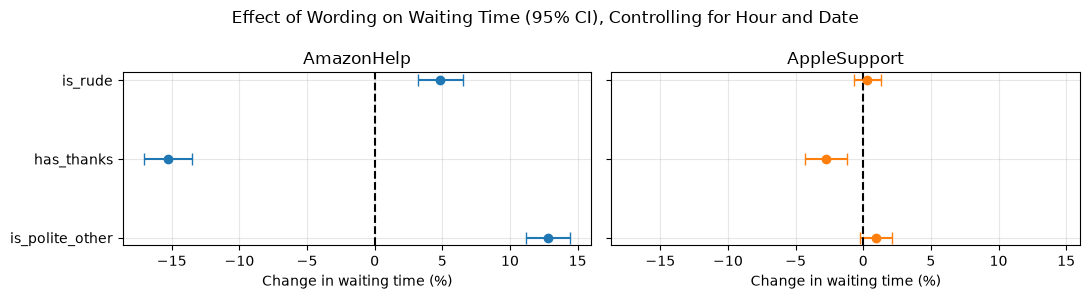

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True, sharey=True)
for ax, (brand, group) in zip(axes, effects.groupby("Brand")):
    y = range(len(group))
    ax.errorbar(group["Effect (%)"], y, fmt="o", capsize=4, color=brand_colors[brand],
                xerr=[group["Effect (%)"] - group["95% CI Low (%)"], group["95% CI High (%)"] - group["Effect (%)"]])
    ax.axvline(0, color="black", linestyle="--")
    ax.set_yticks(list(y), group["Feature"])
    ax.set_title(brand)
    ax.set_xlabel("Change in waiting time (%)")
    ax.grid(alpha=0.3)
plt.suptitle("Effect of Wording on Waiting Time (95% CI), Controlling for Hour and Date")
plt.tight_layout()
plt.show()

#### Time vs Wording: Which Matters More?

Two measures for each brand:
- **Size:** from the regression above, how much slower is the slowest posting hour than the fastest, compared with the largest wording effect?
- **R²:** how much of the variation in (log) waiting time does posting hour alone explain, compared with the wording features alone?

In [30]:
rows = []
for brand, model in models.items():
    group = cases[cases["brand"] == brand]
    hour_coefs = pd.Series({0: 0.0})   # hour 0 is the baseline
    for name, value in model.params.items():
        if name.startswith("C(hour)"):
            hour_coefs[int(name.split("[T.")[1].rstrip("]"))] = value
    rows.append({
        "Brand": brand,
        "Fastest Hour": hour_coefs.idxmin(),
        "Slowest Hour": hour_coefs.idxmax(),
        "Slowest vs Fastest Hour (%)": (np.exp(hour_coefs.max() - hour_coefs.min()) - 1) * 100,
        "Largest Wording Effect (%)": effects.loc[effects["Brand"] == brand, "Effect (%)"].abs().max(),
        "R² Hour Only": smf.ols("log_minutes ~ C(hour)", data=group).fit().rsquared,
        "R² Wording Only": smf.ols("log_minutes ~ " + " + ".join(wording), data=group).fit().rsquared,
    })
pd.DataFrame(rows).set_index("Brand").round(3)

,Fastest Hour,Slowest Hour,Slowest vs Fastest Hour (%),Largest Wording Effect (%),R² Hour Only,R² Wording Only
Brand,,,,,,
AmazonHelp,19,0,103.156,15.304,0.053,0.006
AppleSupport,20,0,1666.554,2.767,0.479,0.006


#### Findings: Wording

- **How common:** 17.5% of tweets contain polite words and 14.6% rude words. In tone groups: 16% Polite, 70% Neutral, 2% Mixed, 13% Rude.
- **At first glance:** AmazonHelp waits are the same for every tone (11.6-13.3 min). AppleSupport looks slower for rude (95 min) and mixed (96 min) tweets than for neutral ones (66 min).
- **But rude tweets are posted at different times.** For Apple, 25.0% of tweets are rude during the iOS bug vs 17.1% outside it, and 22.3% at night vs 17.4% in the morning: exactly when Apple is slow anyway.
- **Within the same time of day** (outside the bug), the gap gets much smaller: in the afternoon, polite, neutral and rude tweets wait 31, 31 and 33 min. In the morning and evening, rude tweets still wait longer (107.1 vs 91.5 min, and 30.0 vs 22.0 min). But each time of day covers 6 hours and mixes fast and slow hours (e.g. Evening includes 23:00, when Apple almost stops replying), so part of this gap may still come from posting time. The regression (next point) compares tweets posted in the same hour on the same day.
- **The regression confirms this.** After controlling for the exact hour and date, rude wording changes Apple's wait by only +0.3% (95% CI -0.7% to +1.3%, not significant). For Amazon, rude tweets wait 4.8% longer (about half a minute).
- **Polite words have small, opposite effects for Amazon:** "thanks" tweets are answered about 15% faster (about 1.8 min), while other polite words (*please, could you, ...*) wait about 13% longer (about 1.5 min). For Apple both are small (-3% and +1%, the latter not significant). One possible reason, not tested here, is that "please" tweets often ask for something new while many "thanks" tweets close a conversation.
- **Time vs wording:** controlling for date and wording, the slowest hour (midnight) is about **2x** slower than the fastest for Amazon and about **18x** for Apple, while no wording effect is larger than 15% (Amazon) or 3% (Apple). Posting hour alone explains 5.3% (Amazon) and 48% (Apple) of the variation in log waiting time; wording explains 0.6% for each brand.

## RQ1 Summary

**Answer to RQ1: for both brands, *when* a customer posts matters more than *how* they write. The gap is huge for AppleSupport and moderate for AmazonHelp.**

**AmazonHelp**
- Posting time: night posts wait 16.4 min vs 9.3 min in the afternoon, and the slowest hour is about 2x the fastest. The pattern stays the same without Black Friday.
- Wording (after controlling for hour and date): small effects. Rude +5%, "please"-type words +13%, "thanks" -15%, each 2 min or less.
- R²: posting hour explains 5.3% of the variation in log waiting time, wording 0.6%.

**AppleSupport**
- Posting time: night posts wait 439 min vs 45 min in the afternoon, and the slowest hour is about 18x the fastest. The night delay remains without the iOS bug period.
- Wording (after controlling for hour and date): tiny effects. Rude +0.3% (not significant), "thanks" -3%.
- R²: posting hour explains 48% of the variation in log waiting time, wording 0.6%.

**Key points**
- **Apple mostly stops replying late at night.** Tweets posted after about 23:00 ET wait until the next morning. This is not caused by the iOS bug. Amazon replies around the clock.
- **Rude tweets only look slower.** They are more common at night and during the iOS bug, when Apple is slow anyway. Compared at the same hour on the same day, rude wording makes almost no difference.
- **Polite wording has small, mixed effects for Amazon** (about 2 min either way) and almost none for Apple.
- **For the waiting-time estimate in the Delivered System,** posting hour is the most useful input, and for Apple also whether the day falls in a peak event (a calendar date itself cannot be used for future questions); wording changes the estimate by only a few minutes.

**Limitations**
- We do not know each customer's real time zone; we use US Eastern Time for everyone.
- Wording is measured only with hand-made word lists, which were not checked by hand. They cannot read sarcasm or context (e.g. sarcastic "thanks"), so some tweets are labeled wrongly, especially as polite.
- The data covers only about 9 weeks (Oct-Dec 2017), with unusual events.
- The regression shows association, not causation: tweets with different wording may also differ in ways we cannot see (e.g. harder problems).

## Influence of Peak Events (RQ2)

**RQ2: How do support teams react to a planned peak and to an unplanned emergency?**

- **Planned peak:** AmazonHelp during Black Friday to Cyber Monday (Nov 24 - 27, 2017).
- **Unplanned emergency:** AppleSupport during the iOS 11.1 keyboard bug (Oct 31 - Nov 9, 2017).

We use the same event dates and US Eastern Time as RQ1, and compare each event with the 14 days just before it (the **baseline**). We look at three measures:
- **Messages per day:** how many customer tweets the team receives. This uses all customer tweets in `cleaned_df`, including those without a reply.
- **Waiting time:** the median and the 90th percentile of `response_minutes`, using the cases from Data Cleaning (first brand reply within 24 hours).
- **Reply rate:** the share of conversation-starting tweets that got a brand reply within 24 hours.

### 1. Daily Customer Messages

We load all tweets and the cases, convert the times to US Eastern Time, and count the customer tweets on each day. The first and last days of the data are incomplete in Eastern Time, so we keep Oct 4 - Dec 1. The shaded areas are the two events.

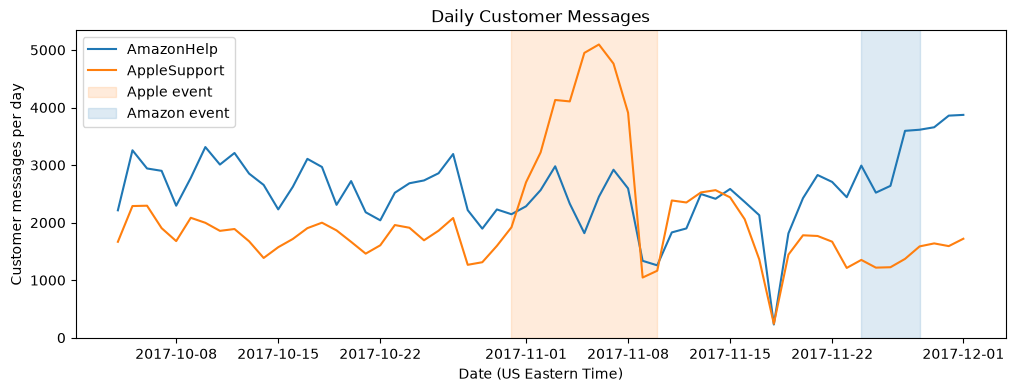

In [31]:
tweets = pd.read_pickle("./data/cleaned_df.pkl")
cases = pd.read_pickle("./data/cases.pkl")

# All customer tweets, including those without a reply
customer = tweets[tweets["inbound"] == True].copy()
customer["brand"] = customer["related_brand"]

# Use US Eastern Time as in RQ1, and keep only full days (the first and last days of the data are incomplete)
customer["local_time"] = customer["created_at"].dt.tz_convert("America/New_York")
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")
customer = customer[(customer["local_time"] >= "2017-10-04") & (customer["local_time"] < "2017-12-02")].copy()
cases = cases[(cases["local_time"] >= "2017-10-04") & (cases["local_time"] < "2017-12-02")].copy()
customer["date"] = customer["local_time"].dt.date
cases["date"] = cases["local_time"].dt.date
cases["weekday"] = cases["local_time"].dt.day_name()

daily_messages = customer.groupby(["date", "brand"]).size().unstack()

plt.figure(figsize=(12, 4))
plt.plot(daily_messages.index, daily_messages["AmazonHelp"], label="AmazonHelp", color=brand_colors["AmazonHelp"])
plt.plot(daily_messages.index, daily_messages["AppleSupport"], label="AppleSupport", color=brand_colors["AppleSupport"])
plt.axvspan(pd.Timestamp("2017-10-31"), pd.Timestamp("2017-11-10"), color=brand_colors["AppleSupport"], alpha=0.15, label="Apple event")
plt.axvspan(pd.Timestamp("2017-11-24"), pd.Timestamp("2017-11-28"), color=brand_colors["AmazonHelp"], alpha=0.15, label="Amazon event")
plt.xlabel("Date (US Eastern Time)")
plt.ylabel("Customer messages per day")
plt.title("Daily Customer Messages")
plt.legend()
plt.show()

In [32]:
# Customer messages per day around the low-count dates
daily_messages.loc[pd.Timestamp("2017-11-06").date():pd.Timestamp("2017-11-20").date()]

brand,AmazonHelp,AppleSupport
date,,
2017-11-06,2450,5095
2017-11-07,2919,4763
2017-11-08,2594,3909
2017-11-09,1336,1046
2017-11-10,1258,1164
2017-11-11,1830,2385
2017-11-12,1899,2350
2017-11-13,2497,2525
2017-11-14,2414,2564


Both brands drop sharply **on the same days**:
- Nov 9 and Nov 10: about half of the usual count (Amazon 1,336 and 1,258, while the weekdays around them have 2,400 - 2,900).
- Nov 18: about one tenth (Amazon 230, Apple 242).

Apple's drop on Nov 9 could partly be real, because the bug was fixed that day, but Amazon drops at the same time, so these days probably have missing data (see also Data Cleaning, Section 5). Nov 9 is in Apple's event, and Nov 10 and Nov 18 are in Amazon's baseline, so Section 4 repeats the comparison without these three days.

### 2. Daily Waiting Time

The median waiting time of the cases posted on each day. The y-axis uses a log scale so both brands fit on one chart, as in RQ1.

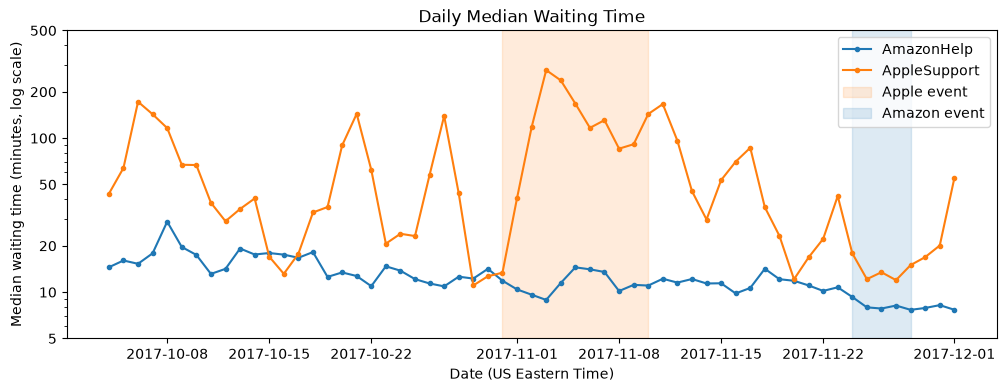

AmazonHelp median wait after Cyber Monday (Nov 28 - Dec 1): 7.9 minutes


,,Apple Median Wait (min)
date,weekday,
2017-10-26,Thursday,57.6
2017-10-27,Friday,139.4
2017-10-28,Saturday,43.8
2017-10-29,Sunday,11.1
2017-10-30,Monday,12.7
2017-10-31,Tuesday,13.4
2017-11-01,Wednesday,40.8
2017-11-02,Thursday,117.7
2017-11-03,Friday,276.5


In [33]:
daily_wait = cases.groupby(["date", "brand"])["response_minutes"].median().unstack()

plt.figure(figsize=(12, 4))
plt.plot(daily_wait.index, daily_wait["AmazonHelp"], marker=".", label="AmazonHelp", color=brand_colors["AmazonHelp"])
plt.plot(daily_wait.index, daily_wait["AppleSupport"], marker=".", label="AppleSupport", color=brand_colors["AppleSupport"])
plt.axvspan(pd.Timestamp("2017-10-31"), pd.Timestamp("2017-11-10"), color=brand_colors["AppleSupport"], alpha=0.15, label="Apple event")
plt.axvspan(pd.Timestamp("2017-11-24"), pd.Timestamp("2017-11-28"), color=brand_colors["AmazonHelp"], alpha=0.15, label="Amazon event")
plt.yscale("log")
plt.yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
plt.xlabel("Date (US Eastern Time)")
plt.ylabel("Median waiting time (minutes, log scale)")
plt.title("Daily Median Waiting Time")
plt.legend()
plt.show()

after = cases[(cases["brand"] == "AmazonHelp") & (cases["local_time"] >= "2017-11-28")]
print("AmazonHelp median wait after Cyber Monday (Nov 28 - Dec 1):", round(after["response_minutes"].median(), 1), "minutes")

# Apple's median wait on each day around its event
apple = cases[cases["brand"] == "AppleSupport"]
apple_daily = pd.DataFrame({"Apple Median Wait (min)": apple.groupby(["date", "weekday"])["response_minutes"].median().round(1)})
apple_daily.loc[pd.Timestamp("2017-10-26").date():pd.Timestamp("2017-11-14").date()]

- **Apple is often slow on Fridays and Saturdays**, also outside the event (the spikes on Oct 6 - 7, Oct 20 - 21, Oct 27 and Nov 10 - 11 in the chart). During the event, it is also slow early in the week: Monday Nov 6 and Tuesday Nov 7 wait 116.6 and 130.8 min, while Monday Oct 30 and Tuesday Oct 31 wait only 12.7 and 13.4 min. Friday Nov 3 and Saturday Nov 4 (276.5 and 237.2 min) are the two slowest days in the data. Nov 3 is also the **iPhone X launch day**, so Apple's event period mixes the iOS 11.1 update and its keyboard bug with a planned product launch.
- **Amazon:** waits drop on Nov 24 and stay low after Cyber Monday (7.9 min from Nov 28 to Dec 1), even though Amazon gets more messages after Cyber Monday (about 3,600 - 3,900 per day) than on any earlier day (Section 1). So the faster replies are not limited to the four event days.

### 3. Baseline vs Event

Each event is compared with the 14 days just before it (US Eastern Time):
- AppleSupport: baseline Oct 17 - 30, event Oct 31 - Nov 9 (10 days)
- AmazonHelp: baseline Nov 10 - 23, event Nov 24 - 27 (4 days)

`Messages per Day` divides the number of customer tweets by the number of days. For the reply rate, a conversation-starting tweet counts as replied if it appears in `cases`, i.e. the brand replied within 24 hours. Every conversation-starting tweet in this dataset has at least one reply (Data Cleaning, Section 2), so this rate cannot show customers who were ignored completely: a tweet counts as not replied when the first brand reply came after 24 hours, or when only someone else replied.

In [34]:
# Baseline (the 14 days before) and event for each brand, in US Eastern Time; the end date is not included
periods = [
    ("AppleSupport", "Baseline", "2017-10-17", "2017-10-31"),
    ("AppleSupport", "Event", "2017-10-31", "2017-11-10"),
    ("AmazonHelp", "Baseline", "2017-11-10", "2017-11-24"),
    ("AmazonHelp", "Event", "2017-11-24", "2017-11-28"),
]
customer["period"] = "Other"
cases["period"] = "Other"
for brand, period, start, end in periods:
    customer.loc[(customer["brand"] == brand) & (customer["local_time"] >= start) & (customer["local_time"] < end), "period"] = period
    cases.loc[(cases["brand"] == brand) & (cases["local_time"] >= start) & (cases["local_time"] < end), "period"] = period

# A conversation-starting tweet counts as replied if it is in cases (first brand reply within 24 hours)
customer["is_first_tweet"] = customer["in_response_to_tweet_id"].isna()
customer["replied_24h"] = customer["tweet_id"].isin(cases["case_id"])

keys = ["brand", "period"]
msgs = customer[customer["period"] != "Other"]
waits = cases[cases["period"] != "Other"]
firsts = msgs[msgs["is_first_tweet"]]

summary = pd.DataFrame({
    "Days": msgs.groupby(keys)["date"].nunique(),
    "Messages per Day": msgs.groupby(keys).size() / msgs.groupby(keys)["date"].nunique(),
    "Median Wait (min)": waits.groupby(keys)["response_minutes"].median(),
    "90th Percentile Wait (min)": waits.groupby(keys)["response_minutes"].quantile(0.9),
    "Reply Rate (conversation starts)": firsts.groupby(keys)["replied_24h"].mean(),
})
summary.round(3)

Days  Messages per Day  Median Wait (min)  \
brand        period                                                
AmazonHelp   Baseline    14          2101.143             11.167   
             Event        4          2936.500              8.350   
AppleSupport Baseline    14          1727.000             46.475   
             Event       10          3583.900            153.808   

                       90th Percentile Wait (min)  \
brand        period                                 
AmazonHelp   Baseline                      31.233   
             Event                         27.365   
AppleSupport Baseline                     400.718   
             Event                        536.992   

                       Reply Rate (conversation starts)  
brand        period                                      
AmazonHelp   Baseline                             0.946  
             Event                                0.956  
AppleSupport Baseline                             0.938  
             Event                                0.903

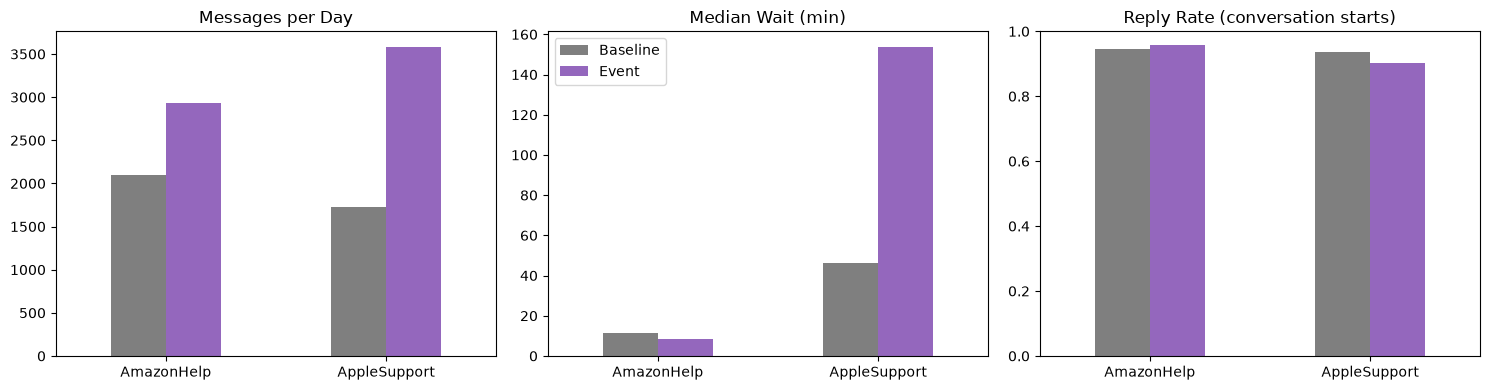

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["Messages per Day", "Median Wait (min)", "Reply Rate (conversation starts)"]):
    summary[column].unstack("period").plot.bar(ax=ax, rot=0, legend=False, color=["tab:gray", "tab:purple"])
    ax.set_title(column)
    ax.set_xlabel("")
axes[1].legend()
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.show()

### 4. Robustness Checks

- **Without the low-count days:** drop Nov 9, Nov 10 and Nov 18 (Section 1), which fall in Apple's event and Amazon's baseline.
- **Conversation-starting tweets only:** follow-up tweets (e.g. "thanks") may be answered differently, so we also compare the median wait of conversation-starting tweets.

In [36]:
# Check 1: drop the three low-count days. Check 2: waiting time of conversation-starting tweets only.
gap_days = [pd.Timestamp("2017-11-09").date(), pd.Timestamp("2017-11-10").date(), pd.Timestamp("2017-11-18").date()]
msgs_ok = msgs[~msgs["date"].isin(gap_days)]
waits_ok = waits[~waits["date"].isin(gap_days)]

robust = pd.DataFrame({
    "Days (no gap days)": msgs_ok.groupby(keys)["date"].nunique(),
    "Messages per Day (no gap days)": msgs_ok.groupby(keys).size() / msgs_ok.groupby(keys)["date"].nunique(),
    "Median Wait (no gap days)": waits_ok.groupby(keys)["response_minutes"].median(),
    "Reply Rate (no gap days)": msgs_ok[msgs_ok["is_first_tweet"]].groupby(keys)["replied_24h"].mean(),
    "Median Wait (conversation starts only)": waits[waits["is_first_tweet"]].groupby(keys)["response_minutes"].median(),
})
robust.round(3)

Days (no gap days)  Messages per Day (no gap days)  \
brand        period                                                         
AmazonHelp   Baseline                  12                        2327.333   
             Event                      4                        2936.500   
AppleSupport Baseline                  14                        1727.000   
             Event                      9                        3865.889   

                       Median Wait (no gap days)  Reply Rate (no gap days)  \
brand        period                                                          
AmazonHelp   Baseline                     11.150                     0.947   
             Event                         8.350                     0.956   
AppleSupport Baseline                     46.475                     0.938   
             Event                       155.733                     0.903   

                       Median Wait (conversation starts only)  
brand        period                                            
AmazonHelp   Baseline                                  10.850  
             Event                                      8.000  
AppleSupport Baseline                                  57.417  
             Event                                    159.350

## RQ2 Summary

**Answer to RQ2: Amazon replied even faster during its planned peak, while Apple's waits became about three times longer during its event period.**

**AmazonHelp (planned peak, Black Friday to Cyber Monday)**
- Messages per day rise by about 40% (2,101 → 2,937).
- The median wait falls from 11.2 to 8.4 min, and the 90th percentile from 31.2 to 27.4 min.
- The reply rate of conversation-starting tweets stays about the same (94.6% → 95.6%).
- Replies stay fast after Cyber Monday too (7.9 min), so the faster replies are not limited to the four event days.

**AppleSupport (unplanned emergency, iOS 11.1 keyboard bug)**
- Messages per day roughly double (1,727 → 3,584).
- The median wait rises from 46.5 to 153.8 min (about 3.3 times), and the 90th percentile from 401 to 537 min.
- The reply rate of conversation-starting tweets falls from 93.8% to 90.3%.
- Apple is often slower on Fridays and Saturdays, but during the event it is also slow early in the week, and Friday Nov 3 and Saturday Nov 4 are the two slowest days in the data. Nov 3 is also the iPhone X launch day.

**Robustness**
- Without Nov 9, 10 and 18, the directions stay the same: Amazon's messages rise by about 26% (2,327 → 2,937) and its median wait still falls (11.2 → 8.4 min); Apple's median wait rises from 46.5 to 155.7 min.
- Conversation-starting tweets only: Amazon 10.9 → 8.0 min, Apple 57.4 → 159.4 min.

**Limitations**
- There is only one event per brand, so differences between the brands (staffing, type of problems) cannot be separated from differences between the events. Apple's demand also grew much more than Amazon's (about +108% vs +40%).
- Apple's event window also contains the iPhone X launch (Nov 3), which was planned, so its slowdown is not caused only by the keyboard bug. We did not check which tweets are about the bug or the launch.
- The data seems to miss part of Nov 9, 10 and 18.
- Every conversation-starting tweet has at least one reply in this dataset, so the reply rate cannot show customers who were ignored completely.
- Amazon's event has 2 weekend days out of 4, while its baseline has 4 out of 14.

## Retrieving Related Cases (RQ3)

**RQ3: When does similar-case search help: keywords (TF-IDF) or semantic embeddings?**

When a customer asks a new question, we want to show similar past cases and how support handled them. We compare two ways to find them:
- **TF-IDF (keywords):** past questions that share rare words with the new question.
- **Sentence embeddings (meaning):** past questions whose meaning is close, even if the words are different.

Both methods rank past cases by cosine similarity and only search cases of the same brand. Sections 1 - 3 build the library of past questions, Sections 4 - 5 find matches with each method, Section 6 compares them, and Section 7 turns the chosen method into a search function for the Delivered System.

### 1. Read Data

We use the cases from Data Cleaning (`cases.pkl`) and all tweets in `cleaned_df.pkl`. The tweets are used to find each customer's earliest tweet and, later, to show whole conversations. As in RQ1 and RQ2, times are converted to US Eastern Time.

A new question starts a conversation, so the library only keeps **first questions**, i.e. cases that pass both checks:
- `is_first_tweet` is `True`: the tweet does not reply to another tweet.
- It is the customer's earliest tweet in the data. Some customers follow up with a new tweet instead of a reply, e.g. "Just to be clear.. I have been home ALL day!". This starts a conversation, but it is not a new question.

Tweets like "still waiting" mean nothing without context. They still appear later, when we show the whole conversation of a case.

All cases: 215852
Conversation starts: 129352
First questions (also the customer's earliest tweet): 112287


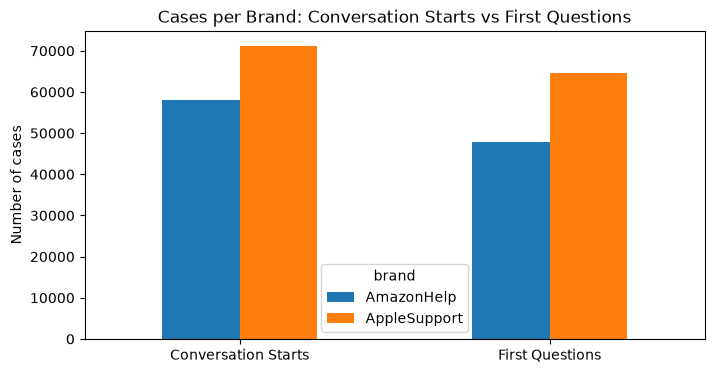

,Conversation Starts,First Questions
brand,,
AmazonHelp,58086,47745
AppleSupport,71266,64542


In [37]:
pd.set_option("display.max_colwidth", None)
cases = pd.read_pickle("./data/cases.pkl")
tweets = pd.read_pickle("./data/cleaned_df.pkl")
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")
print("All cases:", cases.shape[0])

# Keep conversation starts: customer tweets that do not reply to another tweet
cases = cases[cases["is_first_tweet"]].copy()
print("Conversation starts:", cases.shape[0])
before = cases["brand"].value_counts()

# Keep a case only if it is the customer's earliest tweet in the data
customer_first_time = tweets[tweets["inbound"] == True].groupby("author_id")["created_at"].min()
cases = cases[cases["created_at"] == cases["customer_id"].map(customer_first_time)].copy()
print("First questions (also the customer's earliest tweet):", cases.shape[0])

brand_counts = pd.DataFrame({"Conversation Starts": before, "First Questions": cases["brand"].value_counts()}).sort_index()
brand_counts.T.plot(kind="bar", figsize=(8, 4), rot=0, color=brand_colors)
plt.ylabel("Number of cases")
plt.title("Cases per Brand: Conversation Starts vs First Questions")
plt.show()
brand_counts

### 2. Clean Text

`clean_text()` turns tweets into the text used for retrieval, while `customer_text` is kept for display. The same function is used again for replies (Section 6) and for new questions (Section 7), so all texts follow the same rules:
- `html.unescape` turns HTML entities back into symbols, like `&amp;` -> `&`. In this data only `&amp;`, `&lt;` and `&gt;` appear.
- Remove `@` mentions and links, which do not describe the problem.
- Lowercase all letters and join extra spaces.
- Keep punctuation, stop words and emojis, because the embedding model works better on full sentences.

Texts with 3 words or fewer (like "fix this") are removed, because they do not say what the problem is.

In [38]:
def clean_text(texts):
    """Clean tweets for retrieval.

    Input: a pandas Series of raw tweet texts.
    Output: a Series of the same length, with HTML entities decoded, @mentions and
    links removed, all letters in lowercase and extra spaces joined.
    """
    texts = texts.apply(html.unescape)
    texts = texts.str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)
    return texts.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

cases["clean_text"] = clean_text(cases["customer_text"])

# Remove texts with 3 words or fewer
cases["word_count"] = cases["clean_text"].str.split().str.len()
print("Cases before removing short texts:", cases.shape[0])
cases = cases[cases["word_count"] > 3].copy()
print("Cases after removing short texts:", cases.shape[0])
cases[["customer_text", "clean_text"]].head()

Cases before removing short texts: 112287
Cases after removing short texts: 110359


,customer_text,clean_text
0,@AppleSupport Yes I’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.,yes i’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.
2,Apple Podcast is not played continuously on #iOS11 Is there a solution to this problem? @AppleSupport,apple podcast is not played continuously on #ios11 is there a solution to this problem?
5,@AppleSupport since I updated to the most current update the bar which shows how much you’ve listened to doesn’t move https://t.co/VUYr3hkWo0,since i updated to the most current update the bar which shows how much you’ve listened to doesn’t move
6,"@AppleSupport my iPhone used to work fine with my BMW iDrive. After ios11, it won’t work (music and texts)! Please help!","my iphone used to work fine with my bmw idrive. after ios11, it won’t work (music and texts)! please help!"
7,@AppleSupport will there be a fix for the poor #batterylife after update #iOS11 my phone has to be charged several times a day after #SE,will there be a fix for the poor #batterylife after update #ios11 my phone has to be charged several times a day after #se


### 3. Split Data

We split by time, so past cases are used to answer new questions (US Eastern Time):
- `history`: first questions before Nov 27, 2017. This is the library we search in.
- `query`: first questions from Nov 27 to Dec 2, 2017, the last days of the cases. These are the new questions.

A query can never find itself in the library, and each customer has only one first question, so no customer appears in both sets. The history covers the iOS bug and Black Friday periods. Nov 27 is Cyber Monday, so the query set has more Amazon questions than Apple questions, unlike the history. We only search within the brand of the query.

Query period (US Eastern Time): 2017-11-27 00:01:06-05:00 to 2017-12-02 18:12:30-05:00


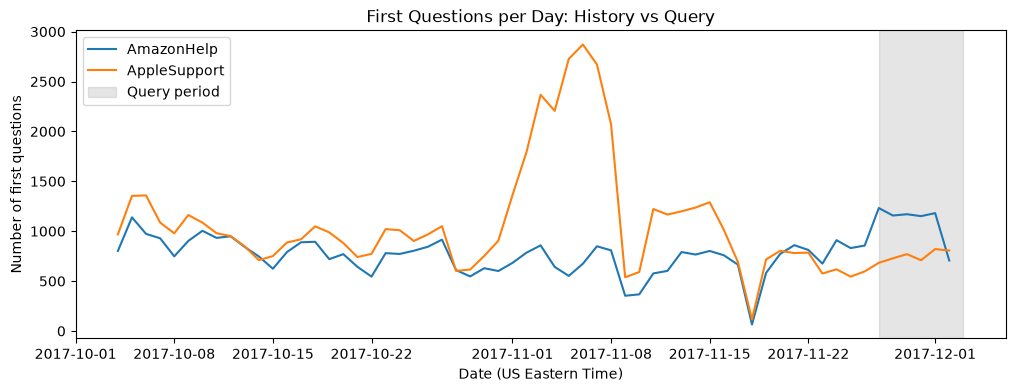

Number of Cases
set     brand                        
history AmazonHelp              40262
        AppleSupport            58983
query   AmazonHelp               6597
        AppleSupport             4517

In [39]:
# Questions from Nov 27 on (US Eastern Time) are the new questions, the rest is the library
cases["set"] = np.where(cases["local_time"] >= "2017-11-27", "query", "history")
history = cases[cases["set"] == "history"].reset_index(drop=True)
query = cases[cases["set"] == "query"].reset_index(drop=True)
print("Query period (US Eastern Time):", query["local_time"].min(), "to", query["local_time"].max())

# First questions per day for each brand, with the query period shaded
day_counts = cases.groupby([cases["local_time"].dt.date, "brand"]).size().unstack()
day_counts = day_counts.loc[pd.Timestamp("2017-10-04").date():]
plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts["AmazonHelp"], label="AmazonHelp", color=brand_colors["AmazonHelp"])
plt.plot(day_counts.index, day_counts["AppleSupport"], label="AppleSupport", color=brand_colors["AppleSupport"])
plt.axvspan(pd.Timestamp("2017-11-27"), pd.Timestamp("2017-12-03"), color="gray", alpha=0.2, label="Query period")
plt.xlabel("Date (US Eastern Time)")
plt.ylabel("Number of first questions")
plt.title("First Questions per Day: History vs Query")
plt.legend()
plt.show()

pd.DataFrame({"Number of Cases": cases.groupby(["set", "brand"]).size()})

### 4. Method A: TF-IDF

TF-IDF turns a tweet into a vector of word weights. A word gets more weight if it appears in this tweet but is rare in the history, so words like "battery" or "refund" matter more than common words.
- Fit on the history only, then transform the queries.
- `stop_words="english"`: drop common words like "the" and "my".
- `min_df=2`: drop words that appear in only one history tweet (typos, order numbers).
- The vectors have length 1, so the product of two vectors is their cosine similarity.

We first look at the top 5 matches of one example query and their conversations, then at the best-match score of 1,000 sample queries.

`get_chain(case_id)` collects a whole conversation: it starts from the first tweet, keeps adding the tweets that reply to the conversation, and sorts them by time. It is used again in Sections 5 and 7.

In [40]:
# Fit TF-IDF on the history only, then transform the queries
tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_tfidf = tfidf.fit_transform(history["clean_text"])
query_tfidf = tfidf.transform(query["clean_text"])
print("Vocabulary size:", len(tfidf.vocabulary_))
print("History matrix:", history_tfidf.shape)
print("Query matrix:", query_tfidf.shape)

Vocabulary size: 14673
History matrix: (99245, 14673)
Query matrix: (11114, 14673)


In [41]:
# Pick one example query
example = query.sample(1, random_state=random_seed).index[0]
print("Brand:", query.loc[example, "brand"])
print("Query:", query.loc[example, "customer_text"])

# Cosine similarity with every history case; the other brand gets -1 so it is never picked
scores = (history_tfidf @ query_tfidf[example].T).toarray().ravel()
scores[(history["brand"] != query.loc[example, "brand"]).to_numpy()] = -1
top = np.argsort(scores)[::-1][:5]
pd.DataFrame({"Score": scores[top], "Case ID": history.loc[top, "case_id"], "History Tweet": history.loc[top, "customer_text"]})

Brand: AppleSupport
Query: @AppleSupport my music app keeps crashing on my iphone 6S. can i get some help with this


,Score,Case ID,History Tweet
83038,0.733390,2493947,my Apple Music keeps crashing :/ help @AppleSupport
46108,0.733390,2548148,"@AppleSupport Help, Apple Music keeps crashing https://t.co/pWDxpyPrDT"
93887,0.681510,118090,@AppleSupport my music app keeps crashing since I updated to iOS 11.1.2 😔
59119,0.669539,1599090,@AppleSupport My IPhone 7 keeps Crashing what should I do?
20983,0.658348,1027615,my music app keeps crashing and won’t open up pls help @AppleSupport


In [42]:
def get_chain(case_id):
    """Return the whole conversation that starts with tweet `case_id`.

    Input: the tweet ID of a first question.
    Output: a DataFrame with the time (US Eastern Time), author and text of every
    tweet in the conversation, sorted by time.
    """
    chain_ids = [case_id]
    while True:
        new_ids = tweets.loc[tweets["in_response_to_tweet_id"].isin(chain_ids) & ~tweets["tweet_id"].isin(chain_ids), "tweet_id"].tolist()
        if len(new_ids) == 0:
            break
        chain_ids = chain_ids + new_ids
    chain = tweets[tweets["tweet_id"].isin(chain_ids)].sort_values("created_at")
    return pd.DataFrame({
        "Time (ET)": chain["created_at"].dt.tz_convert("America/New_York").dt.strftime("%Y-%m-%d %H:%M"),
        "Author": np.where(chain["inbound"], "Customer", chain["author_id"]),
        "Text": chain["text"],
    })

# Show the whole conversation of each top-5 match
for rank, i in enumerate(top):
    print(f"Match {rank + 1}, score {scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.733


,Time (ET),Author,Text
2327781,2017-11-15 12:44,Customer,my Apple Music keeps crashing :/ help @AppleSupport
2327778,2017-11-15 13:17,AppleSupport,@711905 We'd like to look into this with you and get your Apple Music working as expected. What is your iOS version? Does the app load at all?
2327779,2017-11-15 13:24,Customer,"@AppleSupport No it doesn’t load, it’s just a blank screen, I’ve tried restarting my phone and restarting my network settings https://t.co/7z0USJ4M6h"
2327780,2017-11-15 13:49,AppleSupport,"@711905 Those are great steps! Let's move to DM for a closer look. When the app opens to the blank screen, does it seem stuck here, or does it eventually close on its own? https://t.co/GDrqU22YpT"


Match 2, score 0.733


,Time (ET),Author,Text
2380558,2017-10-30 05:28,Customer,"@AppleSupport Help, Apple Music keeps crashing https://t.co/pWDxpyPrDT"
2380557,2017-10-30 09:38,AppleSupport,@166492 Hey. Let's Force Close the Music app and try again with these steps: https://t.co/RqqIctrDWV Let us know how that works.


Match 3, score 0.682


,Time (ET),Author,Text
92721,2017-11-23 05:42,Customer,@AppleSupport my music app keeps crashing since I updated to iOS 11.1.2 😔
92720,2017-11-23 10:29,AppleSupport,@142185 We're glad you reached out. Try these steps with the Music app and let us know how it goes: https://t.co/fUZ0NRJxcn
92719,2017-11-23 16:47,Customer,@AppleSupport Mate have done all those steps. Its harder when it's the built in Apple music app....ios 11 is a joke
92718,2017-11-23 17:12,AppleSupport,@142185 Were you able to delete and reinstall the app? Let us know in DM and we'll continue there. https://t.co/GDrqU22YpT


Match 4, score 0.670


,Time (ET),Author,Text
1454412,2017-11-04 21:21,Customer,@AppleSupport My IPhone 7 keeps Crashing what should I do?
1454411,2017-11-04 23:54,AppleSupport,"@491099 We want to help you. DM us, and we can look into what's going on with your iPhone 7. https://t.co/GDrqU22YpT"


Match 5, score 0.658


,Time (ET),Author,Text
925902,2017-10-14 12:34,Customer,my music app keeps crashing and won’t open up pls help @AppleSupport
925901,2017-10-14 13:23,AppleSupport,@363172 We've got your DM and will continue with you there. Be on the lookout for our reply. Thank you!


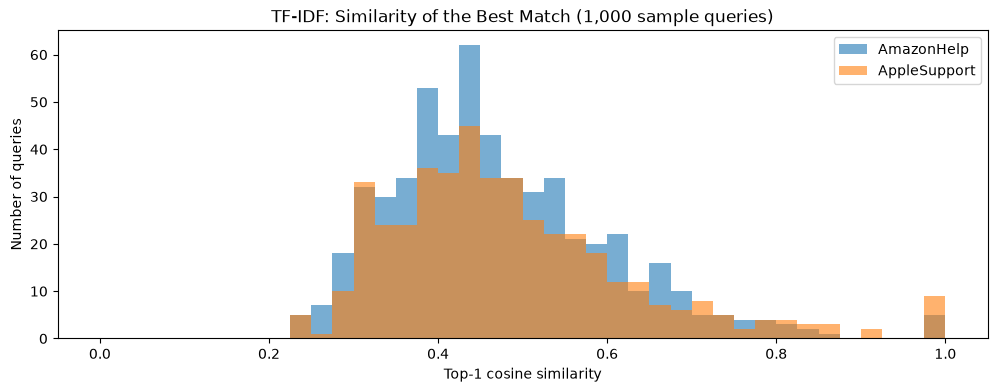

,count,mean,std,min,25%,50%,75%,max
brand,,,,,,,,
AmazonHelp,554.0,0.471247,0.130900,0.231670,0.379687,0.444882,0.541278,1.0
AppleSupport,446.0,0.487022,0.150334,0.226975,0.386821,0.454143,0.559264,1.0


In [43]:
# For 1,000 sample queries, record the best score within the same brand
sample = query.sample(1000, random_state=random_seed)
top1 = []
for i in sample.index:
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    top1.append(scores[(history["brand"] == query.loc[i, "brand"]).to_numpy()].max())
sample["tfidf_top1"] = top1

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp", color=brand_colors["AmazonHelp"])
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport", color=brand_colors["AppleSupport"])
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("TF-IDF: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()
sample.groupby("brand")["tfidf_top1"].describe()

### 5. Method B: Sentence Embeddings

An embedding model turns a tweet into a vector that describes its meaning, not only its words. "package never arrived" and "didn't receive my order" share no words, so TF-IDF cannot link them, but their embeddings are close.
- Model: `all-MiniLM-L6-v2` (sentence-transformers), 384 numbers for each tweet. It is loaded once here as `embedder` and reused in Sections 6 and 7.
- Input is the same `clean_text` as for TF-IDF, to keep the comparison fair.
- Encoding takes several minutes on CPU, so the vectors are saved in `./data/rq3_embeddings.npz` together with the case IDs. A later run reuses them only if the case IDs still match the current history and query; otherwise it encodes the tweets again.

Similarity is computed with NumPy:
- Normalize: divide each vector by its length (`np.linalg.norm`), so the product of two vectors is their cosine similarity. The model output already has length 1; the check below confirms it.
- One query: `history_emb @ query_vector` gives the scores of all history cases.
- Many queries: one matrix product for each brand, then `.max(axis=1)` gives the best score of each query, with no loop over queries.

We use the same example query and the same 1,000 sample queries as in Section 4. The scores of the two methods are on different scales, so the methods are compared in Section 6, not here.

In [44]:
# Load the embedding model once; it is reused in Sections 6 and 7
embedder = SentenceTransformer("all-MiniLM-L6-v2")
emb_file = "./data/rq3_embeddings.npz"

# Reuse saved vectors only if they were made for exactly the same history and query cases
use_saved = False
if os.path.exists(emb_file):
    saved = np.load(emb_file)
    use_saved = (np.array_equal(saved["history_ids"], history["case_id"].to_numpy(dtype="int64"))
                 and np.array_equal(saved["query_ids"], query["case_id"].to_numpy(dtype="int64")))

if use_saved:
    history_emb = saved["history_emb"]
    query_emb = saved["query_emb"]
    print("Loaded the saved vectors")
else:
    start = time.time()
    history_emb = embedder.encode(history["clean_text"].tolist(), batch_size=256)
    query_emb = embedder.encode(query["clean_text"].tolist(), batch_size=256)
    print(f"Encoding time: {time.time() - start:.0f} seconds")
    np.savez(emb_file, history_emb=history_emb, query_emb=query_emb,
             history_ids=history["case_id"].to_numpy(dtype="int64"), query_ids=query["case_id"].to_numpy(dtype="int64"))
print("History vectors:", history_emb.shape, "| Query vectors:", query_emb.shape)

Loaded the saved vectors
History vectors: (99245, 384) | Query vectors: (11114, 384)


In [45]:
# Length of each vector (one number per row)
history_norm = np.linalg.norm(history_emb, axis=1, keepdims=True)
query_norm = np.linalg.norm(query_emb, axis=1, keepdims=True)
print("Vector lengths before normalizing (first 5):", history_norm[:5].ravel().round(3))

# Divide each row by its own length (broadcasting), so every vector has length 1
history_emb = history_emb / history_norm
query_emb = query_emb / query_norm
print("All lengths are 1:", np.allclose(np.linalg.norm(history_emb, axis=1), 1) and np.allclose(np.linalg.norm(query_emb, axis=1), 1))
print("History embeddings:", history_emb.shape, history_emb.dtype, f"{history_emb.nbytes / 1e6:.0f} MB")
print("Query embeddings:", query_emb.shape, query_emb.dtype, f"{query_emb.nbytes / 1e6:.0f} MB")

Vector lengths before normalizing (first 5): [1. 1. 1. 1. 1.]
All lengths are 1: True
History embeddings: (99245, 384) float32 152 MB
Query embeddings: (11114, 384) float32 17 MB


In [46]:
# Same example query as in Section 4: dot product with every history vector
print("Query:", query.loc[example, "customer_text"])
emb_scores = history_emb @ query_emb[example]

# The other brand gets -1 so it is never picked, then take the 5 highest scores
same_brand = (history["brand"] == query.loc[example, "brand"]).to_numpy()
emb_scores[~same_brand] = -1
emb_top = np.argsort(emb_scores)[::-1][:5]
pd.DataFrame({"Score": emb_scores[emb_top], "Case ID": history.loc[emb_top, "case_id"], "History Tweet": history.loc[emb_top, "customer_text"]})

Query: @AppleSupport my music app keeps crashing on my iphone 6S. can i get some help with this


,Score,Case ID,History Tweet
65325,0.869673,1708492,@AppleSupport again the music app keeps crashing without any reason.\nTried restarting and no use.\nSee the video.\niPhone 6 plus - iOS11.0.3 https://t.co/6VpYeHL8aK
95024,0.860225,146730,@AppleSupport Using iPhone 6. Nothing I do fixes the music app crash since iOS 11 update. Cannot use it. Help plse. 😡
12446,0.847268,417293,@AppleSupport iPhone 6 (iOS 11.0.2) Apple Music app crashes every time I launch it. Restartig the phone doesn’t fix the problem.
66285,0.818927,2031727,@AppleSupport my music app crashes for no reason https://t.co/2Kg0ipf4wk
47757,0.817265,2677925,@AppleSupport why does my music app keep crashing


In [47]:
# Show the whole conversation of each top-5 match
for rank, i in enumerate(emb_top):
    print(f"Match {rank + 1}, score {emb_scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.870


,Time (ET),Author,Text
1557694,2017-11-06 19:03,Customer,@AppleSupport again the music app keeps crashing without any reason.\nTried restarting and no use.\nSee the video.\niPhone 6 plus - iOS11.0.3 https://t.co/6VpYeHL8aK
1557692,2017-11-06 19:55,AppleSupport,@517717 Thanks for keeping us posted. Let's get your device fully updated to start. Here's how: https://t.co/80YRnjDFDk
1557693,2017-11-07 05:45,Customer,"@AppleSupport FYI: A college told me today he had the same exact problem last night, the same time like me.. around 01:00 AM Berlin time"


Match 2, score 0.860


,Time (ET),Author,Text
118848,2017-11-24 02:58,Customer,@AppleSupport Using iPhone 6. Nothing I do fixes the music app crash since iOS 11 update. Cannot use it. Help plse. 😡
118847,2017-11-24 09:07,AppleSupport,@149313 We don't want you to miss out on your favorite music! We can help you. Can you tell us what steps you've taken to resolve this? We don't want to ask you to repeat any steps. Send us a DM and let us know. https://t.co/GDrqU22YpT


Match 3, score 0.847


,Time (ET),Author,Text
364837,2017-10-09 22:49,Customer,@AppleSupport iPhone 6 (iOS 11.0.2) Apple Music app crashes every time I launch it. Restartig the phone doesn’t fix the problem.
364836,2017-10-09 23:35,AppleSupport,@214565 Let's figure this out. You've done a great first step. Send us a DM and we'll work through more: https://t.co/GDrqU22YpT


Match 4, score 0.819


,Time (ET),Author,Text
1875679,2017-11-06 23:48,Customer,@AppleSupport my music app crashes for no reason https://t.co/2Kg0ipf4wk
1875678,2017-11-07 09:04,AppleSupport,@600772 We appreciate the screen recording. We'll be glad to help! Please send us a DM including which iOS version is installed. https://t.co/GDrqU22YpT


Match 5, score 0.817


,Time (ET),Author,Text
2508195,2017-10-31 10:04,Customer,@AppleSupport why does my music app keep crashing
2508194,2017-10-31 10:34,AppleSupport,@753618 We'd like to help! Send us a DM With the country that you are located in to continue. https://t.co/GDrqU22YpT


AmazonHelp similarity table: (554, 40262)


AppleSupport similarity table: (446, 58983)
Time for 1,000 queries: 0.11 seconds


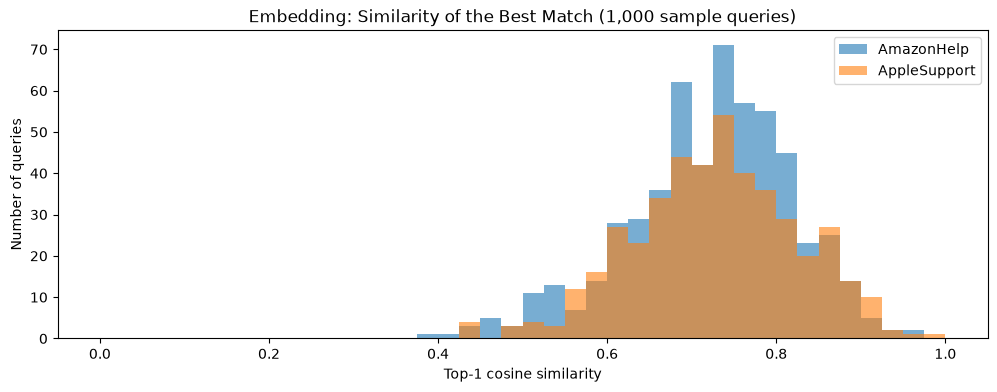

,25th Percentile,Median,75th Percentile
AmazonHelp,0.666791,0.731761,0.788708
AppleSupport,0.659203,0.731066,0.793488


In [48]:
# Same 1,000 sample queries as in Section 4; one matrix product per brand instead of a loop over queries
brands = ["AmazonHelp", "AppleSupport"]
start = time.time()
sample["emb_top1"] = 0.0
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_history = history_emb[(history["brand"] == brand).to_numpy()]
    sim = query_emb[sample.index[rows]] @ brand_history.T
    print(brand, "similarity table:", sim.shape)
    sample.loc[rows, "emb_top1"] = sim.max(axis=1)
print(f"Time for 1,000 queries: {time.time() - start:.2f} seconds")

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp", color=brand_colors["AmazonHelp"])
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport", color=brand_colors["AppleSupport"])
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("Embedding: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()

# Median and quartiles of the best score with NumPy
pd.DataFrame({
    "25th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 25) for b in brands],
    "Median": [np.median(sample.loc[sample["brand"] == b, "emb_top1"]) for b in brands],
    "75th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 75) for b in brands],
}, index=brands)

### 6. Evaluate

No label in the data says which cases are similar, so accuracy cannot be computed directly. We compare the two methods in indirect ways, on the same 1,000 sample queries.

#### 6.1 How Different Are the Results?

If the two methods return the same top 5, there is nothing to compare. So we first count how many cases are in both top-5 lists of each query: 0 means completely different, 5 means identical.

In [49]:
# Top-5 history cases for each sample query: one row per query, one column per rank
k = 5
tfidf_top5 = np.zeros((len(sample), k), dtype=int)
emb_top5 = np.zeros((len(sample), k), dtype=int)

# TF-IDF: one query at a time
for n, i in enumerate(sample.index):
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    scores[(history["brand"] != query.loc[i, "brand"]).to_numpy()] = -1
    tfidf_top5[n] = np.argsort(scores)[::-1][:k]

# Embedding: one matrix product per brand, then sort each row from high to low
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    sim = query_emb[sample.index[rows]] @ history_emb[brand_index].T
    emb_top5[rows] = brand_index[np.argsort(sim, axis=1)[:, ::-1][:, :k]]

print("TF-IDF top-5 table:", tfidf_top5.shape)
print("Embedding top-5 table:", emb_top5.shape)

TF-IDF top-5 table: (1000, 5)
Embedding top-5 table: (1000, 5)


Average number of shared cases: 0.49


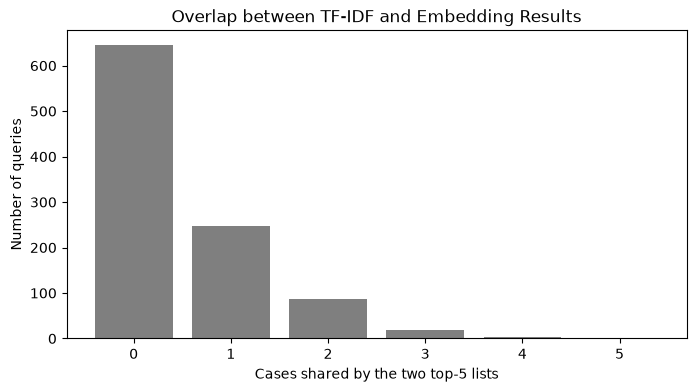

,Shared Cases,Number of Queries
0,0,645
1,1,247
2,2,86
3,3,18
4,4,3
5,5,1


In [50]:
# Count the cases that appear in both top-5 lists of each query
shared = np.array([len(np.intersect1d(tfidf_top5[n], emb_top5[n])) for n in range(len(sample))])
shared_counts = np.bincount(shared, minlength=k + 1)
print("Average number of shared cases:", shared.mean())

plt.figure(figsize=(8, 4))
plt.bar(np.arange(k + 1), shared_counts, color="tab:gray")
plt.xlabel("Cases shared by the two top-5 lists")
plt.ylabel("Number of queries")
plt.title("Overlap between TF-IDF and Embedding Results")
plt.show()
pd.DataFrame({"Shared Cases": np.arange(k + 1), "Number of Queries": shared_counts})

#### 6.2 Reply Similarity

Idea: a similar problem should get a similar reply from support. So we compare the real reply of a query with the replies of its top-5 matches. Higher similarity means better matches.

Two problems:
- Template replies like "send us a dm" make any two cases look similar. So we add a random baseline: 5 random cases of the same brand. A useful method should be clearly better than random.
- The judge may be biased: scoring replies with embeddings may favor the embedding method, and scoring them with TF-IDF may favor TF-IDF. So we use both as judges. If a method wins under both judges, the result is more reliable.

Steps: clean the replies with `clean_text()` after removing agent signatures like `^KH` -> score with each judge -> mean over the 5 matches -> mean over the 1,000 queries.

For the embedding judge, only the history replies that some method picked are encoded. `np.searchsorted` and broadcasting then compute all 1,000 x 5 similarities at once.

In [51]:
# Replies are cleaned like the questions, after removing agent signatures like ^KH
history["reply_clean"] = clean_text(history["reply_text"].str.replace(r"\^\w+", " ", regex=True))
sample["reply_clean"] = clean_text(sample["reply_text"].str.replace(r"\^\w+", " ", regex=True))

# How common are template replies?
print("History replies whose exact text is used more than once:", history["reply_clean"].duplicated(keep=False).sum(), "of", len(history))
pd.DataFrame({"Count": history["reply_clean"].value_counts().head(5)})

History replies whose exact text is used more than once: 19615 of 99245


,Count
reply_clean,
here’s what you can do to work around the issue until it’s fixed in a future software update:,4908
thanks for reaching out. we have a workaround for this here: dm us if you still need help.,581
thanks for reaching out. we're here to help. dm us so we can look into this further with you.,285
we're here to help. let's take this to dm so we can better assist you.,227
let's look into that. send us a dm and we'll go from there.,203


In [52]:
# Random baseline: 5 random history cases of the same brand for each query
rng = np.random.default_rng(random_seed)
random_top5 = np.zeros((len(sample), k), dtype=int)
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    random_top5[rows] = rng.choice(brand_index, size=(rows.sum(), k))
methods = {"Random": random_top5, "TF-IDF": tfidf_top5, "Embedding": emb_top5}

# Judge 1: TF-IDF similarity between the query's real reply and the replies of its 5 matches
reply_tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_reply_tfidf = reply_tfidf.fit_transform(history["reply_clean"])
sample_reply_tfidf = reply_tfidf.transform(sample["reply_clean"])
tfidf_judge = {}
for name, top5 in methods.items():
    tfidf_judge[name] = np.array([(history_reply_tfidf[top5[n]] @ sample_reply_tfidf[n].T).toarray().mean() for n in range(len(sample))])
    print("TF-IDF judge,", name, "mean reply similarity:", tfidf_judge[name].mean().round(3))

TF-IDF judge, Random mean reply similarity: 0.045
TF-IDF judge, TF-IDF mean reply similarity: 0.081
TF-IDF judge, Embedding mean reply similarity: 0.096


In [53]:
# Judge 2: embedding similarity; encode only the history replies that some method picked
needed = np.unique(np.concatenate([random_top5, tfidf_top5, emb_top5]))
needed_reply_emb = embedder.encode(history.loc[needed, "reply_clean"].tolist(), batch_size=256)
sample_reply_emb = embedder.encode(sample["reply_clean"].tolist(), batch_size=256)
needed_reply_emb = needed_reply_emb / np.linalg.norm(needed_reply_emb, axis=1, keepdims=True)
sample_reply_emb = sample_reply_emb / np.linalg.norm(sample_reply_emb, axis=1, keepdims=True)
print("Encoded history replies:", needed_reply_emb.shape)

emb_judge = {}
for name, top5 in methods.items():
    # Position of each matched case in the needed array, then a (1000, 5, 384) block of reply vectors
    matched = needed_reply_emb[np.searchsorted(needed, top5)]
    # Broadcasting: multiply each query reply with its 5 matched replies and sum over the 384 numbers
    sim = (matched * sample_reply_emb[:, np.newaxis, :]).sum(axis=2)
    emb_judge[name] = sim.mean(axis=1)
    print("Embedding judge,", name, "mean reply similarity:", emb_judge[name].mean().round(3))

Encoded history replies: (12523, 384)
Embedding judge, Random mean reply similarity: 0.291
Embedding judge, TF-IDF mean reply similarity: 0.367
Embedding judge, Embedding mean reply similarity: 0.399


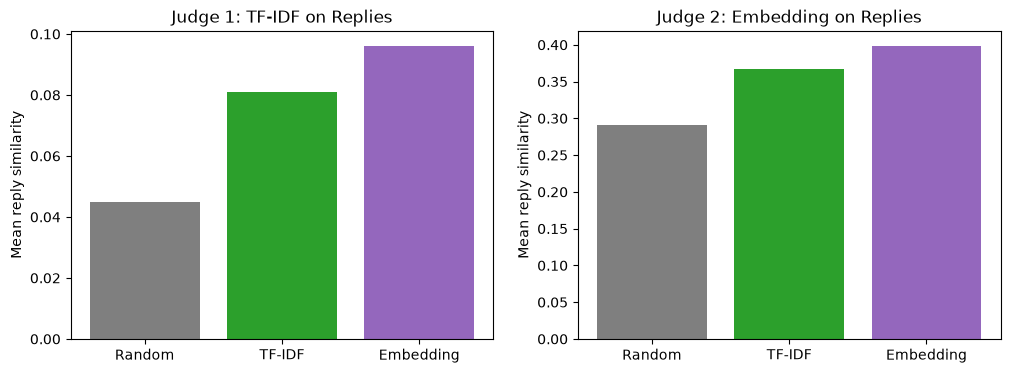

TF-IDF judge: Embedding wins 569 queries, TF-IDF wins 408 queries
Embedding judge: Embedding wins 628 queries, TF-IDF wins 371 queries


,TF-IDF Judge,Embedding Judge
Random,0.044990,0.290862
TF-IDF,0.080858,0.366854
Embedding,0.096183,0.398907


In [54]:
# Mean reply similarity of each method under each judge
summary = pd.DataFrame({
    "TF-IDF Judge": [tfidf_judge[name].mean() for name in methods],
    "Embedding Judge": [emb_judge[name].mean() for name in methods],
}, index=list(methods.keys()))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(summary.index, summary["TF-IDF Judge"], color=["tab:gray", "tab:green", "tab:purple"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 1: TF-IDF on Replies")
plt.subplot(1, 2, 2)
plt.bar(summary.index, summary["Embedding Judge"], color=["tab:gray", "tab:green", "tab:purple"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 2: Embedding on Replies")
plt.show()

# Query by query: how often does one method beat the other?
print("TF-IDF judge: Embedding wins", (tfidf_judge["Embedding"] > tfidf_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (tfidf_judge["TF-IDF"] > tfidf_judge["Embedding"]).sum(), "queries")
print("Embedding judge: Embedding wins", (emb_judge["Embedding"] > emb_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (emb_judge["TF-IDF"] > emb_judge["Embedding"]).sum(), "queries")
summary

#### 6.3 Example Queries

The numbers in 6.2 are averages, so here we look at single queries.
- gap = reply similarity of the embedding method - reply similarity of TF-IDF (embedding judge). gap > 0 means the embedding method did better on this query.
- The histogram shows the gap of all 1,000 queries.
- Then we read the two queries with the largest gap in each direction, with the top 3 matches of both methods and their replies.

Mean gap: 0.032
Queries with a gap between -0.1 and 0.1: 634 of 1000


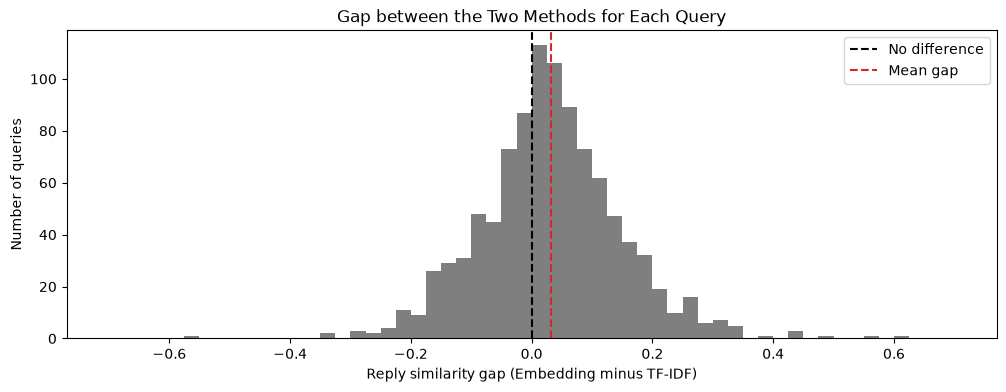

In [55]:
# Gap of each query: positive means the embedding method did better than TF-IDF
gap = emb_judge["Embedding"] - emb_judge["TF-IDF"]
print("Mean gap:", gap.mean().round(3))
print("Queries with a gap between -0.1 and 0.1:", ((gap > -0.1) & (gap < 0.1)).sum(), "of", len(gap))

plt.figure(figsize=(12, 4))
plt.hist(gap, bins=np.linspace(-0.7, 0.7, 57), color="tab:gray")
plt.axvline(0, color="black", linestyle="--", label="No difference")
plt.axvline(gap.mean(), color="tab:red", linestyle="--", label="Mean gap")
plt.xlabel("Reply similarity gap (Embedding minus TF-IDF)")
plt.ylabel("Number of queries")
plt.title("Gap between the Two Methods for Each Query")
plt.legend()
plt.show()

In [56]:
# The two queries with the largest gap in each direction
examples = {"Embedding wins by the most": np.argmax(gap), "TF-IDF wins by the most": np.argmin(gap)}

for title, n in examples.items():
    print(f"{title} (gap {gap[n]:.3f})")
    print("Query:", sample.iloc[n]["customer_text"])
    print("Real reply:", sample.iloc[n]["reply_text"])
    # Top-3 matches of each method and the support reply each one got
    top3 = np.concatenate([tfidf_top5[n, :3], emb_top5[n, :3]])
    display(pd.DataFrame({"Method": ["TF-IDF"] * 3 + ["Embedding"] * 3, "Rank": [1, 2, 3] * 2, "History Tweet": history.loc[top3, "customer_text"].to_numpy(), "Reply": history.loc[top3, "reply_text"].to_numpy()}))

Embedding wins by the most (gap 0.609)
Query: @119625 
Make available more Kannada films we are awaiting
Real reply: @801098 Regional content is an integral part of our content in India. Please stay tuned as we expand our content selection. ^AM


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,@115821 why don't you have Kannada movies in Prime? Cam we expect kannada music in @116935 ???,@136292 Regional content is an integral part of our content in India. Please stay tuned as we expand our content selection. ^AR
1,TF-IDF,2,@129773 Why isn't #WonderWoman available as part of my @129773 account as are so many films are available on Lovefilm DVD but not via Prime?,"@493464 Hey Paul, what do you mean not available? ^RS"
2,TF-IDF,3,anyone else having issues with @129773 today? Can watch any TV show but all films showing as not available in my region???,"@141266 Did you have this issue previously? Also, are you experiencing the same issue on different devices? Let us know. We'd be happy to assist in any way possible. ^SK"
3,Embedding,1,@119625 Please add Kannada language movies. So many prime users from Bangalore are waiting.,@292008 We currently do not have Kannada content on the service. Please stay tuned as we expand our content selection. ^PS
4,Embedding,2,@119625 Any plans to add Kannada movies? Not finding even a single Kannada movie on Amazon prime video. really disappointed..!!😢,@351688 Regional content is an integral part of our content in India. Please stay tuned as we expand our content selection. ^VM
5,Embedding,3,@119625 @AmazonHelp What is stopping you from adding some Kannada language movies and shows? I'm sure many would like to watch..,"@307483 I get your concern, regional content is an integral part of our content in India. 1/2 ^MJ"


TF-IDF wins by the most (gap -0.550)
Query: @AppleSupport hi
why when i create an apple id i dont have a option to select none instead of credit card???
i have sent you a dm plz reply
Real reply: @224794 We're here for you. Your DM has been received. Please look for a reply there from us shortly.


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,@AppleSupport Hi can you reply to my DM?,@438512 We got your DM and will continue there.
1,TF-IDF,2,@AppleSupport hi can someone Dm plz,@125170 Hey there! You can DM us directly by clicking on this link: https://t.co/GDrqU22YpT
2,TF-IDF,3,@AppleSupport please reply to DM,"@497976 We've received your DM, and we'll continue with you there. Be on the lookout for a reply."
3,Embedding,1,@AppleSupport why can’t I remove my credit card from my Apple ID?? 🤔,@432960 We're happy to help. Are you trying to change your payment method or just remove it?
4,Embedding,2,@AppleSupport I can not make a Apple ID AT THE MOMENT please tell me why,@723898 We want to help. Our Apple ID team is best equpped to take a further look at this with you. Reach out to them here: https://t.co/UJm15vmMM2
5,Embedding,3,@AppleSupport I just made a new apple ID to download apps. It says my account has not been reviewed and it doesn’t give me the option of picking none for billing options. I only download free apps. I don’t pay for anything!,"@287163 We completely understand wanting to use the App Store for free apps. Since you must made a new Apple ID, try these steps here: https://t.co/AXK5xJybge If you still have issues, reach out to our iTunes Store experts here: https://t.co/SDIe7UiyJN"


- **Embedding wins by the most:** an AmazonHelp customer asks for more Kannada films. TF-IDF finds one Kannada request first, but its next two matches only share the words "films" and "available" (a film missing on Prime, and films not available in one region). All three embedding matches ask for Kannada movies, and their replies are like the real reply ("stay tuned as we expand our content selection").
- **TF-IDF wins by the most:** an AppleSupport customer cannot choose "None" instead of a credit card when creating an Apple ID, and says they already sent a DM. The real reply only confirms the DM. TF-IDF matches other "please reply to my DM" tweets, whose replies also only talk about the DM. The embedding method finds Apple ID and payment problems, and its third match is the same problem (no "None" billing option), but those replies are about the problem itself. So TF-IDF wins here because of how the real reply was worded, not because its matches are more useful.

#### 6.4 When Does Each Method Win?

To answer *when* each method helps, we split the 1,000 queries into groups and compare the two methods inside each group:
- by brand;
- by question length: short (4 - 10 words), medium (11 - 20 words) and long (21 words or more).

For each group we show the mean gap (Embedding minus TF-IDF) under both judges, and how many queries each method wins under the embedding judge, as in 6.3. A positive gap means the embedding method is better in that group.

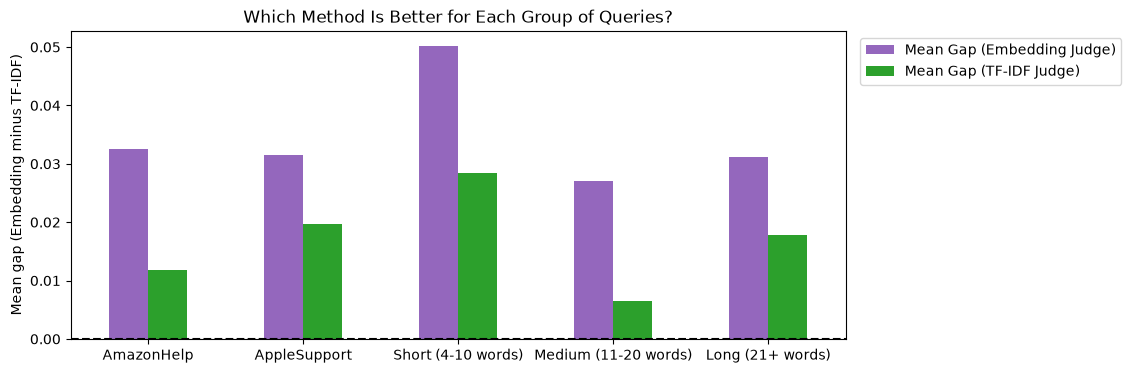

,Queries,Mean Gap (Embedding Judge),Mean Gap (TF-IDF Judge),Embedding Wins,TF-IDF Wins
Group,,,,,
AmazonHelp,554,0.033,0.012,352,201
AppleSupport,446,0.031,0.020,276,170
Short (4-10 words),113,0.050,0.028,78,35
Medium (11-20 words),322,0.027,0.007,204,117
Long (21+ words),565,0.031,0.018,346,219


In [57]:
# Group the 1,000 queries by brand and by question length, then compare the two methods in each group
sample["length"] = pd.cut(sample["word_count"], bins=[3, 10, 20, 1000], labels=["Short (4-10 words)", "Medium (11-20 words)", "Long (21+ words)"])
sample["gap_emb_judge"] = emb_judge["Embedding"] - emb_judge["TF-IDF"]
sample["gap_tfidf_judge"] = tfidf_judge["Embedding"] - tfidf_judge["TF-IDF"]

rows = []
for column in ["brand", "length"]:
    for group, part in sample.groupby(column, observed=True):
        rows.append({
            "Group": group,
            "Queries": len(part),
            "Mean Gap (Embedding Judge)": part["gap_emb_judge"].mean(),
            "Mean Gap (TF-IDF Judge)": part["gap_tfidf_judge"].mean(),
            "Embedding Wins": (part["gap_emb_judge"] > 0).sum(),
            "TF-IDF Wins": (part["gap_emb_judge"] < 0).sum(),
        })
groups = pd.DataFrame(rows).set_index("Group")

groups[["Mean Gap (Embedding Judge)", "Mean Gap (TF-IDF Judge)"]].plot.bar(figsize=(10, 4), rot=0, color=["tab:purple", "tab:green"])
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("")
plt.ylabel("Mean gap (Embedding minus TF-IDF)")
plt.title("Which Method Is Better for Each Group of Queries?")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()
groups.round(3)

- **The embedding method is better in every group**, under both judges: all mean gaps are positive, and it wins more queries than TF-IDF in every group (e.g. 352 vs 201 for AmazonHelp, 276 vs 170 for AppleSupport).
- The two brands are about the same under the embedding judge (0.033 vs 0.031). Under the TF-IDF judge, the advantage is larger for AppleSupport (0.020 vs 0.012).
- By length, short questions (4 - 10 words) show the largest advantage under both judges (0.050 and 0.028), but this group has only 113 queries. Medium questions (11 - 20 words) show the smallest (0.027 and 0.007).
- So in our data there is no group of questions where keywords are better on average. TF-IDF still wins 31 - 39% of single queries in every group; as the Apple ID example in 6.3 shows, some of these wins come from the reply wording rather than from better matches.
- The differences between groups are small and were not tested statistically.

### 7. Search Function for the Delivered System

The embedding method is put into one function, `search()`, which the Delivered System will use: new question -> `clean_text()` -> encode with `embedder` -> most similar past cases of the same brand.
- Library: the last days were kept out only for the evaluation. In real use they are also past cases, so history and query are stacked together, with `pd.concat` for the tables and `np.vstack` for the vectors, in the same row order.
- Saved files: `./data/search_cases.pkl` (cases) and `./data/search_emb.npy` (vectors).
- `search(text, brand, k=5)` returns the `k` most similar cases with their score, case ID, customer tweet, first reply and waiting time. `get_chain(case_id)` shows the whole conversation of a match.

We test it with two made-up questions, then look at the waiting time of the 20 most similar cases. How to turn these into a predicted waiting time is left to the Delivered System.

In [58]:
# The evaluation is done, so the last days join the library: stack tables and vectors in the same order
search_cases = pd.concat([history, query], ignore_index=True)
search_emb = np.vstack([history_emb, query_emb])
print("Library cases:", search_cases.shape[0])
print("Library vectors:", search_emb.shape)
print("Rows match:", search_cases.shape[0] == search_emb.shape[0])

# Keep the columns needed for search and save both files for the Delivered System
search_cases = search_cases[["case_id", "brand", "customer_text", "reply_text", "created_at", "response_minutes"]]
search_cases.to_pickle("./data/search_cases.pkl")
np.save("./data/search_emb.npy", search_emb)

Library cases: 110359
Library vectors: (110359, 384)
Rows match: True


In [59]:
def search(text, brand, k=5):
    """Find the k past cases of `brand` most similar to a new question.

    Input: the question text, the brand ("AmazonHelp" or "AppleSupport") and k.
    Output: a DataFrame with the score, case ID, customer tweet, first reply and
    waiting time (minutes) of the k most similar cases, best first.
    """
    # Clean the question with the same rules as the library, encode it, make its length 1
    clean = clean_text(pd.Series([text]))
    vector = embedder.encode(clean.tolist())[0]
    vector = vector / np.linalg.norm(vector)
    # Cosine similarity with every library case; the other brand gets -1 so it is never picked
    scores = search_emb @ vector
    scores[(search_cases["brand"] != brand).to_numpy()] = -1
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "Score": scores[top],
        "Case ID": search_cases.loc[top, "case_id"].to_numpy(),
        "Customer Tweet": search_cases.loc[top, "customer_text"].to_numpy(),
        "First Reply": search_cases.loc[top, "reply_text"].to_numpy(),
        "Waiting Time (min)": search_cases.loc[top, "response_minutes"].to_numpy(),
    })

In [60]:
# Try two made-up new questions, one for each brand
new_questions = [
    ("My package says delivered but I never received it", "AmazonHelp"),
    ("Battery drains very fast after updating to iOS 11", "AppleSupport"),
]
for text, brand in new_questions:
    print("New question:", text, f"({brand})")
    result = search(text, brand)
    display(result)
    print("Whole conversation of the best match:")
    display(get_chain(result.loc[0, "Case ID"]))

New question: My package says delivered but I never received it (AmazonHelp)


,Score,Case ID,Customer Tweet,First Reply,Waiting Time (min)
0,0.861001,1112103,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH",10.133333
1,0.847082,842259,I never received my @115821 order and it says it was delivered yesterday @AmazonHelp,@320336 Sorry to hear you didn't receive your package! We would love to help. Let's try the steps here: https://t.co/X8TflYmLFV ^SH,44.150000
2,0.838711,2948178,@115821 Its says my package was delivered but it hasnt been,"@814234 I'm sorry you don't have your package, Hero! Please give these steps a try: https://t.co/GmDjuh55FG, and keep us updated on the outcome. ^WJ",6.383333
3,0.832715,1189461,Did not received my package @115850.,@399598 Could you please confirm if we have missed the mentioned time frame? 2/2 ^AH,17.800000
4,0.826213,2888208,@115821 I never received my package :/ says it was delivered. What do I do?,"@800865 I'm sorry for the trouble with delivery, Chloe! Have you tried these steps in regard to finding your package: https://t.co/7LYbk5TtST? Let us know! ^TG",12.050000


Whole conversation of the best match:


,Time (ET),Author,Text
1003609,2017-10-23 22:08,Customer,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG
1003606,2017-10-23 22:18,AmazonHelp,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH"
1003607,2017-10-23 22:19,Customer,@AmazonHelp I did check my mailbox and my neighbors porch just Incase it got delivered to the wrong house
1003608,2017-10-23 22:40,AmazonHelp,"@382462 Sorry you didn't get your package. Sometimes carriers accidentally scan early. If you don't see it by tomorrow, let us know!^EB"


New question: Battery drains very fast after updating to iOS 11 (AppleSupport)


,Score,Case ID,Customer Tweet,First Reply,Waiting Time (min)
0,0.914623,1795316,@AppleSupport Battery draining faster than before after iOS 11.0.3 Update 😐,@539476 We’d be glad to help get to the bottom for this. Can you start by letting us know about this more via DM? https://t.co/GDrqU22YpT,415.466667
1,0.907320,2025149,@115858 @AppleSupport my battery is draining faster than ever on the new iOS 11.0 https://t.co/A72Hv7hsyQ,@598901 Let's see what we can find out! You’ll want to start by backing up and updating to iOS 11.1. DM us if the issue persists. https://t.co/GDrqU22YpT,294.066667
2,0.898212,2059764,"@AppleSupport Battery drains faster even after updating to iOS 11.0.2, needs a fix especially for the battery draining issue.",@609180 We know how vital the battery is. Please check out this article: https://t.co/TpjqFp3jxD \n\nDM us the results. https://t.co/GDrqU22YpT,522.083333
3,0.897160,2029103,@AppleSupport my battery is draining faster than ever on the new iOS 11.1,"@600050 That's not how we want an update to behave! Meet us in DM, tell us which country you're in and we'll take a look. https://t.co/GDrqU22YpT",179.333333
4,0.895723,1975916,facing faster battery drain issues after upgrading to ios 11.1 @AppleSupport @115858,"@585138 Hey there, we'd be happy to look into this with you. DM us and let us know which device this is happening on. We'll go from there. https://t.co/GDrqU22YpT",45.433333


Whole conversation of the best match:


,Time (ET),Author,Text
1642123,2017-10-12 02:40,Customer,@AppleSupport Battery draining faster than before after iOS 11.0.3 Update 😐
1642119,2017-10-12 09:35,AppleSupport,@539476 We’d be glad to help get to the bottom for this. Can you start by letting us know about this more via DM? https://t.co/GDrqU22YpT
1642120,2017-10-12 09:43,Customer,@AppleSupport @539476 @AppleSupport you don’t know the resolution. You people haven’t resolved yet even iOS updated to 11.0.3
1692491,2017-10-17 23:22,Customer,@539476 @AppleSupport My phone is now useless. Battery totally drained within two hours after updating 11.0.3. WTF ? And.... you forced me to make this update.
1692490,2017-10-18 08:37,AppleSupport,@552829 We'd like to take a closer look at this with you. Let us know what type of iPhone you're using; we'll go from there. https://t.co/GDrqU22YpT
1721433,2017-10-21 22:36,Customer,@539476 @AppleSupport Huge battery drain on ios 11 updates for iPhone. iPad unaffected.
1721430,2017-10-21 23:59,AppleSupport,@559956 We'd like to look into what's happening with your iPhone battery performance. Please send a DM telling which iPhone you have. https://t.co/GDrqU22YpT
1721431,2017-10-22 07:14,Customer,"@AppleSupport @559956 Liz you are lucky my iPad mini 4 gets maybe 2 hours before I have to plug it in, keyboard lag apps crash list goes on"
1721432,2017-10-22 10:34,Customer,@176402 @AppleSupport So sorry to hear that! That must be annoying as all get out.
1642121,2017-10-26 05:18,Customer,@AppleSupport @539476 Why the battery of iphone 7 plus is getting drained very soon after the new software update???


Median waiting time of the 20 similar cases: 114.2 minutes
Median waiting time of all AppleSupport first questions in the library: 90.2 minutes


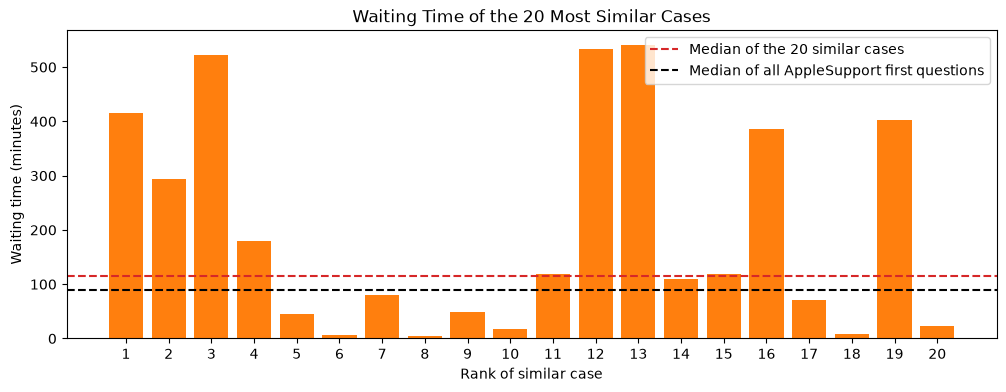

In [61]:
# Waiting time of the 20 most similar cases, compared with all AppleSupport first questions in the library
similar = search("Battery drains very fast after updating to iOS 11", "AppleSupport", k=20)
brand_median = np.median(search_cases.loc[search_cases["brand"] == "AppleSupport", "response_minutes"])
similar_median = np.median(similar["Waiting Time (min)"])
print("Median waiting time of the 20 similar cases:", similar_median.round(1), "minutes")
print("Median waiting time of all AppleSupport first questions in the library:", brand_median.round(1), "minutes")

plt.figure(figsize=(12, 4))
plt.bar(np.arange(1, 21), similar["Waiting Time (min)"], color=brand_colors["AppleSupport"])
plt.axhline(similar_median, color="tab:red", linestyle="--", label="Median of the 20 similar cases")
plt.axhline(brand_median, color="black", linestyle="--", label="Median of all AppleSupport first questions")
plt.xticks(np.arange(1, 21))
plt.xlabel("Rank of similar case")
plt.ylabel("Waiting time (minutes)")
plt.title("Waiting Time of the 20 Most Similar Cases")
plt.legend()
plt.show()

## RQ3 Summary

**Answer to RQ3: semantic embeddings find slightly more helpful similar cases than keywords (TF-IDF). This holds for both brands and for short, medium and long questions, but the advantage is small.**

**Key results** (1,000 sample queries from Nov 27 - Dec 2)
- The two methods return very different cases: on average only 0.49 of the 5 matches are shared, and 645 queries share none.
- Both methods are clearly better than random under both judges. TF-IDF judge: random 0.045, TF-IDF 0.081, embedding 0.096. Embedding judge: random 0.291, TF-IDF 0.367, embedding 0.399.
- The embedding method wins more queries under both judges (569 vs 408, and 628 vs 371), but the mean gap is only 0.032, and 634 queries have a gap between -0.1 and 0.1.
- **When:** the embedding method is better in every group we checked (both brands; short, medium and long questions). We found no group where keywords are better on average.
- **Examples:** for the example query "my music app keeps crashing on my iphone 6S", both methods find Music app crashes, but one of the 5 TF-IDF matches is a general iPhone crash ("My IPhone 7 keeps Crashing"). All 5 embedding matches are Music app crashes, and the top 3 mention an iPhone 6, close to the customer's iPhone 6S. In 6.3, the embedding method finds three other requests for Kannada films, while two of the top 3 TF-IDF matches only share the words "films" and "available".

**Decision:** the Delivered System uses the embedding method (`search()` in Section 7). Search is fast enough for an interactive tool: with one matrix product per brand, 1,000 queries take about 0.1 seconds (Section 5). TF-IDF stays a useful baseline: it needs no model download, it is easy to explain, and its matches share the exact words of the question.

**Limitations**
- Reply similarity is an indirect measure: the same problem can get replies in different words, and about 20% of the history replies are reused templates. In 6.3, TF-IDF wins the Apple ID query only because the real reply just confirms a DM.
- The embedding judge uses the same kind of model as the embedding method, so it may favor it. The TF-IDF judge points the same way, but with a smaller gap.
- Only 1,000 queries from the last 6 days are tested, and the matches were not checked by hand.
- The differences between the groups in 6.4 are small and were not tested statistically.

## Delivered System

The Delivered System puts the three research questions together. A customer writes a new question, chooses the brand and gives the posting time, and the support team tells the system whether a peak event (a big sale or a software problem) is going on. The system answers with:

- **Expected waiting time and its usual range:** the median and the 25th - 75th percentiles of past waiting times for the same brand, posting hour and peak status (RQ1 Section 1, RQ2), adjusted by the wording effects of the RQ1 regression.
- **A tip:** the posting hour with the shortest median wait (RQ1).
- **Similar past cases:** the most similar past questions and their replies, found with `search()` from RQ3, to read while waiting.

RQ3 Section 7 left open how to turn the waiting times of similar cases into an estimate. We do not use them for the estimate: these cases were posted at different hours, and RQ1 showed that posting hour explains much more of the waiting time (48% for AppleSupport) than wording (0.6%). So the estimate uses posting hour and peak status, and the similar cases are shown as examples.

No new method is added in this part: every step reuses a method or a result from the sections above.

### 1. The SupportAssistant Class

The system is one class, `SupportAssistant`. An object of this class keeps everything the system needs, and its methods answer new questions.

Attributes, built once in `__init__`:
- `wait_table`: for each brand, peak status and posting hour (US Eastern Time), the number of past cases and the 25th percentile, median and 75th percentile of their waiting time. The cases are the first questions of the RQ3 search library (`search_cases`, 110,359 cases), because a new question starts a conversation. The peak status uses the same event dates as RQ1 and RQ2 (`events`).
- `effects`: the wording effects of the RQ1 regression (`effects`), e.g. -15% for "thanks" words at AmazonHelp.
- `word_lists`: the RQ1 word lists for "thanks" words, other polite words and rude words.

Methods:
- `find_wording(text)`: which word lists appear in the text, after removing @mentions and links as in RQ1.
- `estimate_wait(text, brand, post_time, is_peak)`: looks up the median and the 25th - 75th percentiles in `wait_table`, then multiplies them by the RQ1 effect of each wording feature found.
- `ask(text, brand, post_time, is_peak, k)`: prints the estimate, its usual range and the fastest posting hour, then shows the `k` most similar past cases with `search()` from RQ3.

Checks:
- A wrong brand is an input error that can happen, so `estimate_wait()` raises a `ValueError`, which the caller can catch with `try` / `except`.
- `assert` checks things that should never fail: the table has every brand, peak status and hour, and the estimate is positive.

In [62]:
class SupportAssistant:
    """The Delivered System: expected waiting time (RQ1, RQ2) and similar past cases (RQ3).

    Input: `library`, past first questions with `brand`, `created_at` (UTC) and
    `response_minutes`; `events`, the peak event dates of each brand (US Eastern Time,
    end date not included); `effects`, the wording effects (%) of the RQ1 regression;
    `word_lists`, the RQ1 word list of each wording feature.
    """

    def __init__(self, library, events, effects, word_lists):
        data = library.copy()
        local_time = data["created_at"].dt.tz_convert("America/New_York")
        data["hour"] = local_time.dt.hour
        data["is_peak"] = False
        for brand, (start, end) in events.items():
            data.loc[(data["brand"] == brand) & (local_time >= start) & (local_time < end), "is_peak"] = True

        # Median and quartiles of the waiting time for each brand, peak status and posting hour
        groups = data.groupby(["brand", "is_peak", "hour"])["response_minutes"]
        self.wait_table = pd.DataFrame({
            "Cases": groups.size(),
            "25th Percentile (min)": groups.quantile(0.25),
            "Median Wait (min)": groups.median(),
            "75th Percentile (min)": groups.quantile(0.75),
        })
        self.brands = sorted(data["brand"].unique())
        assert len(self.wait_table) == len(self.brands) * 2 * 24, "every brand, peak status and hour needs past cases"

        # Wording effect of each (brand, feature), e.g. ("AmazonHelp", "has_thanks") -> -15.3
        self.effects = effects.set_index(["Brand", "Feature"])["Effect (%)"]
        self.word_lists = word_lists

    def find_wording(self, text):
        """Return the wording features (keys of `word_lists`) found in a text, as in RQ1."""
        text = pd.Series([text]).str.replace(r"@\w+", "", regex=True).str.replace(r"http\S+", "", regex=True)
        found = []
        for feature, words in self.word_lists.items():
            pattern = r"\b(?:" + "|".join(words) + r")\b"
            if text.str.contains(pattern, case=False, regex=True)[0]:
                found.append(feature)
        return found

    def estimate_wait(self, text, brand, post_time, is_peak=False):
        """Estimate the waiting time of a new question.

        Input: the question, the brand, the posting time in US Eastern Time
        (e.g. "2017-12-05 23:30") and whether a peak event is going on.
        Output: a dict with the expected wait, its usual range (25th - 75th percentile,
        in minutes) and the wording features found.
        """
        if brand not in self.brands:
            raise ValueError(f"brand must be one of {self.brands}, not {brand!r}")
        hour = pd.Timestamp(post_time).hour
        row = self.wait_table.loc[(brand, is_peak, hour)]

        # Each wording feature changes the wait by its RQ1 effect
        wording = self.find_wording(text)
        factor = 1.0
        for feature in wording:
            factor = factor * (1 + self.effects[(brand, feature)] / 100)

        estimate = row["Median Wait (min)"] * factor
        assert estimate > 0, "the expected wait must be positive"
        return {
            "Expected Wait (min)": estimate,
            "Low (min)": row["25th Percentile (min)"] * factor,
            "High (min)": row["75th Percentile (min)"] * factor,
            "Wording": wording,
        }

    def ask(self, text, brand, post_time, is_peak=False, k=5):
        """Answer a new question: expected wait, the fastest posting hour and k similar past cases (RQ3)."""
        result = self.estimate_wait(text, brand, post_time, is_peak)
        medians = self.wait_table.loc[(brand, is_peak), "Median Wait (min)"]
        print("Question:", text)
        print(f"Brand: {brand} | Posted: {post_time} (ET) | Peak event: {'yes' if is_peak else 'no'}")
        print(f"Expected waiting time: about {result['Expected Wait (min)']:.0f} minutes "
              f"(usually {result['Low (min)']:.0f} - {result['High (min)']:.0f} minutes)")
        print("Wording found:", ", ".join(result["Wording"]) if result["Wording"] else "none")
        print(f"Tip: questions posted at {medians.idxmin()}:00 ET wait the least (median {medians.min():.0f} minutes)")
        print(f"\nThe {k} most similar past cases, to read while waiting:")
        similar = search(text, brand, k)
        display(similar)
        return similar

### 2. Waiting-Time Table

We build the assistant from the results above and plot its table in the same style as RQ1 Section 1: the median waiting time for each posting hour, on normal days (solid line) and during the brand's peak event (dashed line). The table under the chart shows how many first questions each part is based on, and its fastest and slowest posting hours.

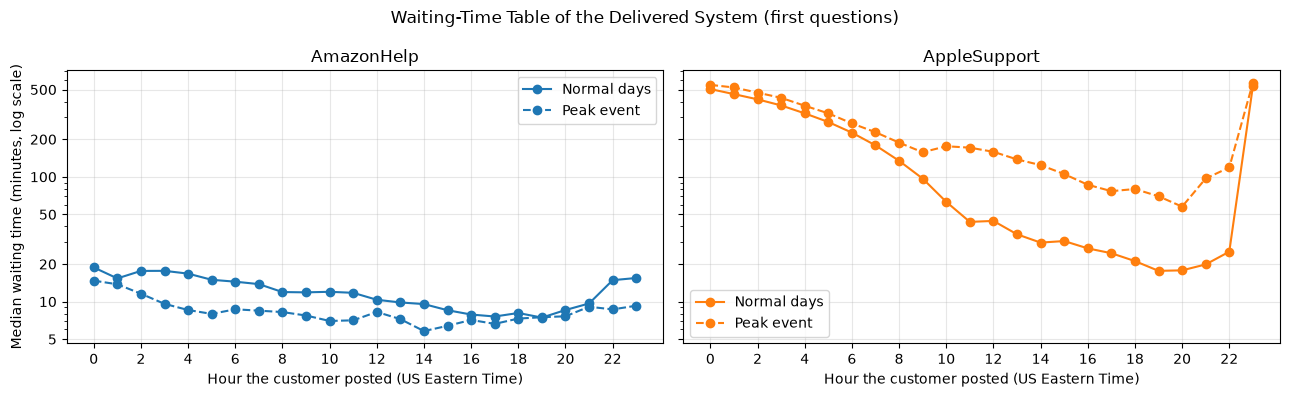

First Questions  Fastest Hour  \
Brand        Peak Event                                  
AmazonHelp   False                 43030            19   
             True                   3829            14   
AppleSupport False                 43992            19   
             True                  19508            20   

                         Median at Fastest Hour (min)  Slowest Hour  \
Brand        Peak Event                                               
AmazonHelp   False                                7.4             0   
             True                                 5.8             0   
AppleSupport False                               17.6            23   
             True                                57.7            23   

                         Median at Slowest Hour (min)  
Brand        Peak Event                                
AmazonHelp   False                               18.8  
             True                                14.7  
AppleSupport False                              532.4  
             True                               567.4

In [63]:
# Build the system from earlier results: RQ3 library, RQ1/RQ2 event dates, RQ1 wording effects and word lists
assistant = SupportAssistant(
    library=search_cases,
    events=events,
    effects=effects,
    word_lists={"has_thanks": thanks_words, "is_polite_other": other_polite_words, "is_rude": rude_words},
)

# Median wait by posting hour: normal days (solid) and the brand's peak event (dashed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, brand in zip(axes, assistant.brands):
    for is_peak, style, label in [(False, "-", "Normal days"), (True, "--", "Peak event")]:
        medians = assistant.wait_table.loc[(brand, is_peak), "Median Wait (min)"]
        ax.plot(medians.index, medians.values, linestyle=style, marker="o", color=brand_colors[brand], label=label)
    ax.set_yscale("log")
    ax.set_yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
    ax.set_xticks(range(0, 24, 2))
    ax.set_title(brand)
    ax.set_xlabel("Hour the customer posted (US Eastern Time)")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Median waiting time (minutes, log scale)")
plt.suptitle("Waiting-Time Table of the Delivered System (first questions)")
plt.tight_layout()
plt.show()

# Size of each part of the table, and its fastest and slowest posting hours
rows = []
for brand in assistant.brands:
    for is_peak in [False, True]:
        part = assistant.wait_table.loc[(brand, is_peak)]
        rows.append({
            "Brand": brand,
            "Peak Event": is_peak,
            "First Questions": part["Cases"].sum(),
            "Fastest Hour": part["Median Wait (min)"].idxmin(),
            "Median at Fastest Hour (min)": part["Median Wait (min)"].min(),
            "Slowest Hour": part["Median Wait (min)"].idxmax(),
            "Median at Slowest Hour (min)": part["Median Wait (min)"].max(),
        })
pd.DataFrame(rows).set_index(["Brand", "Peak Event"]).round(1)

- **AppleSupport on normal days:** the median wait falls from about 500 minutes for questions posted around midnight to 17.6 minutes at 19:00, then jumps to 532 minutes at 23:00. This is the night pattern of RQ1, now for first questions only.
- **AppleSupport during its peak event:** slower at every hour, especially in the afternoon and evening, as in RQ2. The fastest hour is 20:00, with a median of 57.7 minutes.
- **AmazonHelp:** the median wait stays between about 6 and 19 minutes at every hour, and during its peak event (Black Friday to Cyber Monday) it is faster than on normal days at most hours, as in RQ2.
- The peak parts of the table are based on fewer cases (3,829 first questions for AmazonHelp and 19,508 for AppleSupport), so they are less precise.

### 3. Try the System

We try the system with made-up questions posted on Dec 5, 2017, just after the end of the data (US Eastern Time):
- **Full answer:** an AppleSupport question posted late at night on a normal day.
- **What if:** the same questions with a different posting hour, peak status or wording. The changes should agree with RQ1 and RQ2.
- **Wrong input:** a brand that the system does not know.

In [64]:
# Full answer for an AppleSupport question posted late at night on a normal day
matches = assistant.ask("My iPhone keeps freezing after the iOS 11 update, can you help?", "AppleSupport", "2017-12-05 23:30")
print("Whole conversation of the most similar case:")
display(get_chain(matches.loc[0, "Case ID"]))

Question: My iPhone keeps freezing after the iOS 11 update, can you help?
Brand: AppleSupport | Posted: 2017-12-05 23:30 (ET) | Peak event: no
Expected waiting time: about 532 minutes (usually 519 - 544 minutes)
Wording found: none
Tip: questions posted at 19:00 ET wait the least (median 18 minutes)

The 5 most similar past cases, to read while waiting:


,Score,Case ID,Customer Tweet,First Reply,Waiting Time (min)
0,0.940918,2122587,@AppleSupport is there any way to fix that my iPhone constantly freezes since updating to iOS 11?,@625312 We can definitely look into this together and find a solution. Reach out to us in DM and we’ll help. https://t.co/GDrqU22YpT,327.433333
1,0.935670,2045934,@AppleSupport My phone keeps freezing after the iOS 11.1 update. Any tips?,@605060 Let's take a look in DM. Let us know which iPhone you have and if it freezes in a specific app. We'll work together there. https://t.co/GDrqU22YpT,50.016667
2,0.919544,2078967,@AppleSupport since I updated to iOS 11 my phone has been freezing up constantly @115858,@614859 We're here to help. Send us a DM with your current iOS version and model of iPhone. We'll get started there. https://t.co/GDrqU22YpT,93.383333
3,0.917276,930867,"@AppleSupport ever since I updated my iPhone to the highest iOS 11 update, its been freezing many times a day and I have to manually restart",@340811 We're happy to look into this with you. Please DM us the exact iOS 11 version installed &amp; we'll find a solution. https://t.co/GDrqU22YpT,29.850000
4,0.909808,1596727,My phone started freezing after iOS 11.1 update have been released and installed thanks @115858,"@490533 Thanks for reaching out. Does this occur when using a specific app? Let us know, we'd like the details to assist.",235.150000


Whole conversation of the most similar case:


,Time (ET),Author,Text
1966459,2017-11-08 05:25,Customer,@AppleSupport is there any way to fix that my iPhone constantly freezes since updating to iOS 11?
1966458,2017-11-08 10:53,AppleSupport,@625312 We can definitely look into this together and find a solution. Reach out to us in DM and we’ll help. https://t.co/GDrqU22YpT


In [65]:
# The same questions with a different posting hour, peak status or wording
apple_question = "My iPhone keeps freezing after the iOS 11 update, can you help?"
amazon_question = "My package says delivered but I never received it"
scenarios = [
    ("AppleSupport", apple_question, "2017-12-05 14:00", False),
    ("AppleSupport", apple_question, "2017-12-05 23:30", False),
    ("AppleSupport", apple_question, "2017-12-05 14:00", True),
    ("AppleSupport", "My iPhone keeps freezing after the iOS 11 update, this is ridiculous", "2017-12-05 14:00", False),
    ("AmazonHelp", amazon_question, "2017-12-05 14:00", False),
    ("AmazonHelp", amazon_question, "2017-12-05 03:00", False),
    ("AmazonHelp", amazon_question, "2017-12-05 14:00", True),
    ("AmazonHelp", "Thanks! " + amazon_question, "2017-12-05 14:00", False),
]
rows = []
for brand, text, post_time, is_peak in scenarios:
    result = assistant.estimate_wait(text, brand, post_time, is_peak)
    rows.append({
        "Brand": brand,
        "Question": text,
        "Posted (ET)": post_time,
        "Peak Event": is_peak,
        "Wording Found": ", ".join(result["Wording"]),
        "Expected Wait (min)": round(result["Expected Wait (min)"], 1),
        "Usual Range (min)": f"{result['Low (min)']:.0f} - {result['High (min)']:.0f}",
    })
pd.DataFrame(rows)

,Brand,Question,Posted (ET),Peak Event,Wording Found,Expected Wait (min),Usual Range (min)
0,AppleSupport,"My iPhone keeps freezing after the iOS 11 update, can you help?",2017-12-05 14:00,False,,29.7,13 - 69
1,AppleSupport,"My iPhone keeps freezing after the iOS 11 update, can you help?",2017-12-05 23:30,False,,532.4,519 - 544
2,AppleSupport,"My iPhone keeps freezing after the iOS 11 update, can you help?",2017-12-05 14:00,True,,124.2,72 - 222
3,AppleSupport,"My iPhone keeps freezing after the iOS 11 update, this is ridiculous",2017-12-05 14:00,False,is_rude,29.8,13 - 69
4,AmazonHelp,My package says delivered but I never received it,2017-12-05 14:00,False,,9.6,5 - 20
5,AmazonHelp,My package says delivered but I never received it,2017-12-05 03:00,False,,17.6,8 - 27
6,AmazonHelp,My package says delivered but I never received it,2017-12-05 14:00,True,,5.8,3 - 10
7,AmazonHelp,Thanks! My package says delivered but I never received it,2017-12-05 14:00,False,has_thanks,8.1,4 - 17


In [66]:
# A brand the system does not know is an input error, so we catch it with try / except
try:
    assistant.ask("Where is my order?", "Netflix", "2017-12-05 14:00")
except ValueError as error:
    print("Input error:", error)

Input error: brand must be one of ['AmazonHelp', 'AppleSupport'], not 'Netflix'


- **Full answer:** the AppleSupport question posted at 23:30 is expected to wait about 532 minutes, i.e. until the next morning, with a narrow usual range (519 - 544 minutes). The tip says that questions posted at 19:00 usually wait only about 18 minutes. All 5 similar cases are about an iPhone freezing after the iOS 11 update, and four of their replies ask the customer to continue in a DM. Their own waits range from 30 to 327 minutes, because they were posted at different hours; this is why the estimate uses the posting hour instead of these waits.
- **What if:** every change agrees with the research questions.
  - Posting hour (RQ1): the Apple question waits 29.7 minutes at 14:00 but 532.4 minutes at 23:30. The Amazon question waits 9.6 minutes at 14:00 and 17.6 minutes at 03:00.
  - Peak event (RQ2): at 14:00, Apple's estimate rises from 29.7 to 124.2 minutes, while Amazon's falls from 9.6 to 5.8 minutes.
  - Wording (RQ1): rude words change Apple's estimate by only 0.1 minute (29.7 to 29.8), and "thanks" lowers Amazon's from 9.6 to 8.1 minutes (-15%).
- **Wrong input:** the unknown brand "Netflix" raises a `ValueError`, which is caught and printed instead of stopping the notebook.

## Conclusion

- **RQ1 (posting time and wording):** when a customer posts matters much more than how they write. AppleSupport mostly stops replying late at night (night posts wait about 10 times longer than afternoon posts), while AmazonHelp replies around the clock. After controlling for hour and date, wording changes the wait by only a few percent.
- **RQ2 (planned peak vs unplanned emergency):** AmazonHelp replied even faster during its planned peak (median 11.2 to 8.4 minutes), while AppleSupport's median wait rose about 3.3 times during the iOS 11.1 keyboard bug period, which also included the iPhone X launch.
- **RQ3 (similar-case search):** semantic embeddings find slightly more helpful similar cases than keywords (TF-IDF), for both brands and for short, medium and long questions, but the advantage is small.
- **Delivered System:** `SupportAssistant` puts these results together. Posting hour and peak status give the expected wait, wording changes it slightly, and the embedding search shows similar past cases to read while waiting. For example, the same AppleSupport question is expected to wait about 30 minutes at 14:00 but about 9 hours at 23:30.

**Limitations**
- The data covers only about 9 weeks at the end of 2017 and two brands, with one peak event each.
- We use US Eastern Time for every customer.
- The expected wait comes from past medians and was not tested on new questions, and the peak status must be given by the support team.